# MAC × CADTestBench：API 生成与评测

通过 DeepSeek API 运行 [MAC](https://github.com/Pan-Chera/Multi-Agent-CAD) 单零件多智能体工作流，
生成 STEP 模型，经 CadQuery 桥接后执行 [CADTestBench](https://github.com/dimitrismallis/CADTestBench) 官方测试。

按顺序运行全部单元：环境与实验配置 → 数据校验 → API 生成与修复 → 官方评分 → 指标及 CAD 可视化。
所有角色使用 `deepseek-flash`，密钥从 `DEEPSEEK_API_KEY` 环境变量或隐藏输入读取。
结果写入本次独立的 `outputs/` 目录，最后展示 PR、RS、无效样本比例和分类测试通过率。


## 0. 运行环境

从项目根目录打开 Notebook。首次将 `INSTALL_ENVIRONMENTS=True`，运行安装单元；
安装后改回 `False`，切换到 `MAC · CADTestBench (eval)` 内核，重启并从顶部运行。

- `mac-gen`：MAC、build123d 和 API 客户端。
- `mac-eval`：CadQuery、官方评分、Notebook 和绘图。

两个环境通过 STEP 和 JSON 交接，避免 CAD 内核版本冲突。尚未安装 Jupyter 时，在终端执行：

```bash
conda create -y -n mac-eval python=3.12 pip jupyterlab
conda run -n mac-eval jupyter lab MAC_API_CADTestBench.ipynb
```


In [1]:
from pathlib import Path
import json
import shutil
import subprocess
import sys

INSTALL_ENVIRONMENTS = False
PROJECT = Path.cwd().resolve()
if not (PROJECT / 'third_party/Multi-Agent-CAD/pyproject.toml').is_file():
    raise RuntimeError('请从解压后的 mac_api_cadtestbench 项目根目录打开 Notebook。')

commands = [
    ['conda', 'create', '-y', '-n', 'mac-eval', 'python=3.12', 'pip'],
    ['conda', 'run', '-n', 'mac-eval', 'python', '-m', 'pip', 'install',
     '-r', str(PROJECT / 'requirements-eval.txt')],
    ['conda', 'run', '-n', 'mac-eval', 'python', '-m', 'ipykernel', 'install',
     '--user', '--name', 'mac-eval', '--display-name', 'MAC · CADTestBench (eval)'],
    ['conda', 'create', '-y', '-n', 'mac-gen', 'python=3.12', 'pip'],
    ['conda', 'run', '-n', 'mac-gen', 'python', '-m', 'pip', 'install',
     '-c', str(PROJECT / 'constraints-mac-cpu.txt'),
     '-e', str(PROJECT / 'third_party/Multi-Agent-CAD') + '[mesh]'],
    ['conda', 'run', '-n', 'mac-gen', 'python', '-m', 'pip', 'check'],
]
if INSTALL_ENVIRONMENTS:
    if not shutil.which('conda'):
        raise RuntimeError('当前启动 Jupyter 的环境找不到 conda；先安装或从 Conda 终端启动 Jupyter。')
    installed_envs = {Path(p).name for p in json.loads(
        subprocess.check_output(['conda', 'env', 'list', '--json'], text=True))['envs']}
    for command in commands:
        if command[1] == 'create' and command[command.index('-n') + 1] in installed_envs:
            print('已有环境，跳过创建：', command[command.index('-n') + 1])
            continue
        print('执行：', ' '.join(command), flush=True)
        subprocess.run(command, check=True)
    print('环境已创建。请将 INSTALL_ENVIRONMENTS 改回 False，切换到 MAC · CADTestBench (eval) 内核，重启后从顶部运行。')
else:
    print('默认跳过安装。首次使用时将 INSTALL_ENVIRONMENTS=True；已有环境直接往下执行。')


默认跳过安装。首次使用时将 INSTALL_ENVIRONMENTS=True；已有环境直接往下执行。


## 1. 实验配置

固定使用 DeepSeek API；设置样本数量、分区和修复次数。`N_SAMPLES=None` 评测所选分区的完整 200 题。


In [2]:
from datetime import datetime, timezone
import hashlib
import os
import uuid
import pandas as pd
from IPython.display import display, Image

ROOT = PROJECT
MAC_SOURCE = ROOT / 'third_party/Multi-Agent-CAD'
CTB_SOURCE = ROOT / 'third_party/CADTestBench'
CTB_DATA_DIR = ROOT / 'data/CADTestBench'
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(CTB_SOURCE / 'src'))

API_BASE_URL = 'https://api.deepseek.com'
API_MODEL = 'deepseek-flash'
API_KEY_ENV = 'DEEPSEEK_API_KEY'
N_SAMPLES = None                      # 每分区样本数；None 表示完整 200 题
PARTITIONS = ['detailed']
SEED = 20261101
REPAIR_BUDGET = 2
MAX_API_CALLS_PER_TASK = 20
JUDGE_ENABLED = True
MAC_PYTHON = ['conda', 'run', '--no-capture-output', '-n', 'mac-gen', 'python']

MAC_COMMIT = '487f94b7064e935c1a9a2f9b426525d5c94cd857'
CTB_CODE_COMMIT = 'e29283cc61db7329039d95b429766a50bfd37f89'
CTB_DATA_REVISION = '2b9a4a972d142d2bc634d072e9d4485f171ced06'
EXPERIMENT_LABEL = f'mac_api_deepseek_{API_MODEL}_text'
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6]
RUN_DIR = ROOT / 'outputs' / (EXPERIMENT_LABEL + '_' + stamp)
RUN_DIR.mkdir(parents=True)


def sha(value):
    return hashlib.sha256(value).hexdigest()


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding='utf-8')


print('模型：', API_MODEL)
print('本次结果目录：', RUN_DIR)


模型： deepseek-flash
本次结果目录： C:\Users\xuyq\Desktop\MAC_API_CADTestBench_project\mac_api_cadtestbench\outputs\mac_api_deepseek_deepseek-flash_text_20261101T080600Z_ecab62


## 2. 数据与样本

校验固定版本代码和官方数据，按种子确定样本顺序。`abstract` 和 `detailed` 是相同物体的两种描述，分别评分。
生成阶段只使用官方 prompt，测试内容不进入智能体。


In [3]:
def verify_snapshot(root, manifest, path_key):
    for item in manifest['files']:
        path = Path(root) / item[path_key]
        if not path.is_file() or sha(path.read_bytes()) != item['sha256']:
            raise ValueError(f'固定版本文件缺失或已修改：{path}')

data_manifest = json.loads((CTB_DATA_DIR / 'download_manifest.json').read_text(encoding='utf-8'))
ctb_manifest = json.loads((CTB_SOURCE / 'source_manifest.json').read_text(encoding='utf-8'))
mac_manifest = json.loads((MAC_SOURCE / 'source_manifest.json').read_text(encoding='utf-8'))
assert data_manifest['revision'] == CTB_DATA_REVISION
assert ctb_manifest['commit'] == CTB_CODE_COMMIT
assert mac_manifest['commit'] == MAC_COMMIT
verify_snapshot(CTB_DATA_DIR, data_manifest, 'repo_path')
verify_snapshot(CTB_SOURCE, ctb_manifest, 'path')
verify_snapshot(MAC_SOURCE, mac_manifest, 'path')

sample_tables = {p: pd.read_parquet(CTB_DATA_DIR / 'samples' / f'{p}.parquet')
                 for p in ['abstract', 'detailed']}
ids = sorted(sample_tables['detailed']['sample_id'].tolist())
assert len(ids) == len(set(ids)) == 200
assert ids == sorted(sample_tables['abstract']['sample_id'].tolist())
if not PARTITIONS or set(PARTITIONS) - {'abstract', 'detailed'}:
    raise ValueError('PARTITIONS 只能从 abstract / detailed 中选择。')
if N_SAMPLES is not None and (not isinstance(N_SAMPLES, int) or not 1 <= N_SAMPLES <= 200):
    raise ValueError('N_SAMPLES 取 1–200 或 None。')
ordered_ids = sorted(ids, key=lambda sid: sha(f'{SEED}:{sid}'.encode()))
selected_ids = ordered_ids if N_SAMPLES is None else ordered_ids[:N_SAMPLES]
cases_by_partition = {}
for p in PARTITIONS:
    table = sample_tables[p].set_index('sample_id')
    cases_by_partition[p] = [{'sample_id': sid, 'partition': p, 'prompt': table.loc[sid, 'prompt']}
                             for sid in selected_ids]

protocol = {
    'run_kind': 'real_api_inference',
    'experiment_label': EXPERIMENT_LABEL, 'mac_commit': MAC_COMMIT,
    'cadtestbench_commit': CTB_CODE_COMMIT, 'dataset_revision': CTB_DATA_REVISION,
    'selection': 'SHA256(seed:sample_id), ascending, first N', 'seed': SEED,
    'partitions': PARTITIONS, 'sample_ids': selected_ids,
    'full_partition': len(selected_ids) == 200,
    'model': API_MODEL, 'api_base_url': API_BASE_URL,
    'repair_budget': REPAIR_BUDGET, 'max_api_calls_per_task': MAX_API_CALLS_PER_TASK,
    'sdk_automatic_retries': 0, 'judge_enabled': JUDGE_ENABLED, 'multimodal': 'never',
    'artifact_policy': 'final explicit state STEP, including internal QA failure',
    'missing_artifact_policy': 'keep original task in official denominator',
    'test_feedback_to_agents': False,
}
save_json(RUN_DIR / 'protocol.json', protocol)
print(f'每个分区评测 {len(selected_ids)} 题，共 {len(PARTITIONS)} 个分区。')
display(pd.DataFrame(cases_by_partition[PARTITIONS[0]]).head(3))


每个分区评测 200 题，共 1 个分区。


,sample_id,partition,prompt
0,00985494,detailed,Write Python code using CADQuery to create a r...
1,00039681,detailed,Write Python code using CADQuery to create a s...
2,00033624,detailed,Write Python code using CADQuery to create a l...


## 3. API 密钥

读取 `DEEPSEEK_API_KEY`；未设置时通过隐藏输入获取。密钥只保留在进程环境中。


In [4]:
from getpass import getpass

if not os.environ.get(API_KEY_ENV):
    os.environ[API_KEY_ENV] = getpass(f'输入 {API_KEY_ENV}（隐藏输入）：').strip()
if not os.environ.get(API_KEY_ENV):
    raise RuntimeError('API Key 为空，请配置后再运行。')


## 4. MAC 生成工作流

运行原始 Planner → Architect → Coder → 检查与修复流程。每题使用独立进程和目录，保存最终 STEP 与运行状态。
保留请求次数限制、超时处理及 OCP 兼容处理。


In [7]:
import re
import signal
import time

MAC_STAGES = ("SPEC_PLANNER", "ARCHITECT", "CODER", "REPAIR", "JUDGE")

API_WORKER_CODE = r'''
from pathlib import Path
from enum import Enum
import importlib.util
import io
import json
import os
import sys
import time
import traceback

job = json.loads(Path(sys.argv[1]).read_text(encoding="utf-8"))
cwd = Path.cwd()
active_key = os.environ.get("MAC_ACTIVE_API_KEY", "")

def clean(value):
    if isinstance(value, str):
        return value.replace(active_key, "[REDACTED_API_KEY]") if active_key else value
    if isinstance(value, dict):
        return {clean(str(k)): clean(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [clean(v) for v in value]
    return value

class RedactedOutput(io.TextIOBase):
    def __init__(self, wrapped):
        self.wrapped, self.pending = wrapped, ""
    def write(self, text):
        self.pending += str(text)
        while "\n" in self.pending:
            line, self.pending = self.pending.split("\n", 1)
            self.wrapped.write(clean(line) + "\n")
        return len(text)
    def flush(self):
        if self.pending:
            self.wrapped.write(clean(self.pending))
            self.pending = ""
        self.wrapped.flush()
    @property
    def encoding(self):
        return getattr(self.wrapped, "encoding", "utf-8")
    def isatty(self):
        return False

sys.stdout = RedactedOutput(sys.stdout)
sys.stderr = RedactedOutput(sys.stderr)
os.environ["MAC_CONFIG_FILE"] = str(cwd / "mac_config.json")
# The upstream direct-client function reads this historical env name even for
# non-DashScope endpoints. The credential is never written into that JSON.
os.environ["DASHSCOPE_API_KEY"] = active_key
os.environ.pop("MAC_CHILD_ENV_ALLOW", None)  # retain upstream child env allowlist
sys.path.insert(0, job["mac_source"])
sys.path.insert(0, str(Path(job["mac_source"]) / "packages/cadpy/src"))

started = time.monotonic()
last_state = {}
api_calls = 0
exit_code = 1
compatibility_patches = []

class RequestBudgetExceeded(BaseException):
    pass

def serializable(value):
    if hasattr(value, "model_dump"):
        return serializable(value.model_dump(mode="json"))
    if isinstance(value, Enum):
        return value.value
    if isinstance(value, dict):
        return {str(k): serializable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [serializable(v) for v in value]
    if isinstance(value, Path):
        return str(value)
    if value is None or isinstance(value, (str, int, float, bool)):
        return value
    return str(value)

def write_json(name, value):
    path = cwd / name
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(clean(serializable(value)), ensure_ascii=False,
                                    indent=2), encoding="utf-8")
    temporary.replace(path)

def existing_artifact(key):
    raw = last_state.get(key)
    if not raw:
        return None
    path = Path(raw)
    path = (path if path.is_absolute() else cwd / path).resolve()
    if cwd not in path.parents or not path.is_file() or path.stat().st_size == 0:
        return None
    return str(path)

def save_snapshot(status, error=None):
    keep = ["error_type", "iteration_count", "node_history", "cad_brief",
            "architect_plan", "qa_report", "judge_decision", "execution_log"]
    result = {k: last_state.get(k) for k in keep if k in last_state}
    for key in ("current_step_path", "current_stl_path", "current_python_code_path"):
        result[key] = existing_artifact(key)
    result.update({
        "sample_id": job["sample_id"], "status": status,
        "upstream_commit": job["upstream_commit"],
        "configuration": "MAC single-part, cloud API, text-only, direct API repair",
        "model": job["model"],
        "elapsed_seconds": time.monotonic() - started,
        "artifact_policy": "last state STEP, including internal QA failures",
        "eligible_for_external_evaluation": bool(result["current_step_path"]),
        "official_benchmark_tests_used_for_generation": False,
        "compatibility_patches": compatibility_patches,
        "error": error,
    })
    write_json("final_state.json", result)

try:
    if not active_key:
        raise RuntimeError("The requested API credential was not passed to the worker")
    if importlib.util.find_spec("aider") is not None:
        raise RuntimeError("Use the dedicated MAC environment without aider-chat for this direct API configuration")
    from OCP.BRepGProp import BRepGProp
    if not hasattr(BRepGProp, "Volume"):
        BRepGProp.Volume = staticmethod(BRepGProp.VolumeProperties_s)
        compatibility_patches.append("OCP BRepGProp.Volume -> VolumeProperties_s")
    from openai import OpenAI
    from openai.resources.chat.completions import Completions
    original_create = Completions.create
    import multi_agent_cad.graph as graph
    import multi_agent_cad.nodes as nodes

    def api_client():
        return OpenAI(base_url=job["base_url"], api_key=active_key, max_retries=0)

    def bounded_create(self, *args, **kwargs):
        global api_calls
        if api_calls >= job["max_api_calls"]:
            raise RequestBudgetExceeded("Per-task API invocation budget reached")
        api_calls += 1
        kwargs["extra_body"] = {"thinking": {"type": "disabled"}}
        try:
            return original_create(self, *args, **kwargs)
        except Exception as exc:
            raise RuntimeError(clean(f"{type(exc).__name__}: {exc}")) from None

    nodes._llm_client = api_client
    Completions.create = bounded_create
    graph._MAX_SELF_RETRIES = job["self_retry_attempts"]
    last_state = graph.get_default_initial_state(workflow_id="original")
    last_state.update(user_request=job["prompt"], force_refresh=True)
    save_snapshot("running")
    app = graph.build_graph()
    for value in app.stream(last_state, {"recursion_limit": 50}, stream_mode="values"):
        last_state = dict(value)
        save_snapshot("running")
    exit_code = graph.pipeline_exit_code(last_state)
    save_snapshot("completed" if exit_code == 0 else "completed_internal_failure")
except BaseException as exc:
    save_snapshot("api_budget_exhausted" if isinstance(exc, RequestBudgetExceeded)
                  else "worker_error", clean(f"{type(exc).__name__}: {exc}"))
    traceback.print_exc()
    exit_code = 1
sys.stdout.flush()
sys.stderr.flush()
sys.exit(exit_code)
'''


In [8]:
def run_mac_one_api(prompt, sample_id, *, output_root, job_timeout_seconds=3600):
    """Run one official prompt in an independent MAC process."""
    credential = os.environ.get(API_KEY_ENV, '')
    if not credential:
        raise RuntimeError(f'请先配置 {API_KEY_ENV}。')
    if not isinstance(prompt, str) or not prompt.strip():
        raise ValueError('prompt must be a nonempty official prompt string')
    if MAX_API_CALLS_PER_TASK < 1 or REPAIR_BUDGET < 0:
        raise ValueError('API call limit must be positive; repair budget must be nonnegative')
    if not (MAC_SOURCE / 'multi_agent_cad/graph.py').is_file():
        raise FileNotFoundError(f'MAC source is missing at {MAC_SOURCE}')
    if any(credential in value for value in (prompt, str(sample_id), API_MODEL, API_BASE_URL)):
        raise ValueError('An API credential was found in the task configuration')

    name = re.sub(r'[^A-Za-z0-9_.-]+', '_', str(sample_id)).strip('._') or 'sample'
    run_id = time.strftime('%Y%m%dT%H%M%S') + '_' + uuid.uuid4().hex[:8]
    workdir = Path(output_root).resolve() / name / run_id
    workdir.mkdir(parents=True, exist_ok=False)
    cfg = {
        'DS_BASE_URL': API_BASE_URL, 'DS_API_KEY': '',
        'API_KEY_ENV_VAR': 'OPENAI_API_KEY', 'API_BASE_ENV_VAR': 'OPENAI_API_BASE',
        'MAX_RETRIES': REPAIR_BUDGET, 'MAX_EXEC_RETRIES': 0,
        'LLM_API_TIMEOUT': 180, 'LLM_CODEGEN_API_TIMEOUT': 180,
        'CAD_SCRIPT_TIMEOUT': 180, 'CHECK_MESH_TIMEOUT': 180,
        'CHECKPOINT_INPUT_TIMEOUT': 0, 'INTERVENTION_INPUT_TIMEOUT': 0,
        'SPEC_PLANNER_MULTIMODAL': 'never', 'JUDGE_MULTIMODAL': 'never',
        'JUDGE_ENABLED': JUDGE_ENABLED, 'JUDGE_MIN_RETRY': 1,
        'AIDER_MODEL': 'openai/' + API_MODEL, 'AIDER_MAX_TOKENS': 4096,
        'USER_REQUEST': prompt,
    }
    for stage in MAC_STAGES:
        cfg[stage + '_MODEL'] = API_MODEL
        cfg[stage + '_KWARGS'] = {}
        cfg[stage + '_TEMPERATURE'] = 0.0
        cfg[stage + '_MAX_TOKENS'] = 1024 if stage == 'JUDGE' else 4096
    job = {
        'sample_id': str(sample_id), 'prompt': prompt,
        'prompt_sha256': sha(prompt.encode('utf-8')),
        'mac_source': str(MAC_SOURCE), 'upstream_commit': MAC_COMMIT,
        'base_url': API_BASE_URL, 'model': API_MODEL,
        'max_api_calls': MAX_API_CALLS_PER_TASK, 'self_retry_attempts': 1,
        'official_benchmark_tests_used_for_generation': False,
    }
    save_json(workdir / 'job.json', job)
    save_json(workdir / 'mac_config.json', cfg)
    worker_path = workdir / 'mac_worker.py'
    worker_path.write_text(API_WORKER_CODE, encoding='utf-8')
    command = list(MAC_PYTHON) + [str(worker_path), str(workdir / 'job.json')]
    env = os.environ.copy()
    for variable in ('PYTHONPATH', 'PYTHONHOME', 'OPENAI_LOG'):
        env.pop(variable, None)
    env['MAC_ACTIVE_API_KEY'] = credential
    env['PYTHONIOENCODING'] = 'utf-8'
    started = time.monotonic()
    timed_out = False
    with (workdir / 'run.log').open('w', encoding='utf-8') as log:
        process = subprocess.Popen(command, cwd=workdir, env=env, stdin=subprocess.DEVNULL,
                                   stdout=log, stderr=subprocess.STDOUT,
                                   start_new_session=(os.name == 'posix'))
        try:
            process.wait(timeout=job_timeout_seconds)
        except (subprocess.TimeoutExpired, KeyboardInterrupt):
            timed_out = True
            if os.name == 'posix':
                os.killpg(process.pid, signal.SIGTERM)
            else:
                process.terminate()
            try:
                process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                if os.name == 'posix':
                    os.killpg(process.pid, signal.SIGKILL)
                else:
                    process.kill()
                process.wait()
    state_path = workdir / 'final_state.json'
    result = json.loads(state_path.read_text(encoding='utf-8')) if state_path.is_file() else {
        'sample_id': str(sample_id), 'status': 'worker_failed_before_state',
        'current_step_path': None, 'eligible_for_external_evaluation': False,
    }
    if timed_out:
        result['status'] = 'timeout_or_interrupted'
    result.update(workdir=str(workdir), returncode=process.returncode, model=API_MODEL,
                  wall_seconds=time.monotonic() - started,
                  final_state_json=str(state_path), run_log=str(workdir / 'run.log'))
    serialized_result = json.dumps(result, ensure_ascii=False, indent=2).replace(credential, '[REDACTED_API_KEY]')
    (workdir / 'run_result.json').write_text(serialized_result, encoding='utf-8')
    return json.loads(serialized_result)


## 5. STEP → CadQuery

将最终 STEP 桥接为官方评测输入，保留全部实体及其尺寸、位置。


In [9]:
def bridge_step_to_cadtestbench(step_path, method_root, sample_id):
    """Write generated_models/<sample_id>/{generated.step,gpt_generated.py}."""
    if not isinstance(sample_id, str) or not sample_id.isdecimal():
        raise ValueError("Use the original numeric sample_id string, including zeros")
    source = Path(step_path).expanduser().resolve(strict=True)
    if not source.is_file():
        raise ValueError(f"STEP input is not a file: {source}")
    folder = Path(method_root).expanduser().resolve() / "generated_models" / sample_id
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / "generated.step"
    if source != target:
        shutil.copy2(source, target)
    code = '''from pathlib import Path
import cadquery as cq

_loaded = cq.importers.importStep(str(Path(__file__).with_name("generated.step")))
_solids = _loaded.solids().vals()
if not _solids:
    raise ValueError("STEP artifact contains no solids")
# Keep every solid in one Workplane value; do not fuse, rescale, rotate, or repair.
_shape = _solids[0] if len(_solids) == 1 else cq.Compound.makeCompound(_solids)
final_result = cq.Workplane(obj=_shape)
'''
    script = folder / "gpt_generated.py"
    script.write_text(code, encoding="utf-8")
    return script


## 6. 批量生成

按样本列表调用 API、执行生成代码并桥接最终产物。生成失败的样本仍保留在评测列表中。


In [10]:
generation_records = []
method_roots = {}
for partition, cases in cases_by_partition.items():
    method_root = RUN_DIR / partition / 'final'
    method_roots[partition] = method_root
    (method_root / 'generated_models').mkdir(parents=True, exist_ok=True)
    for i, case in enumerate(cases, 1):
        sid = case['sample_id']
        print(f'[{partition} {i}/{len(cases)}] {sid}', flush=True)
        try:
            result = run_mac_one_api(case['prompt'], sid,
                                     output_root=RUN_DIR / partition / 'generation' / 'jobs')
        except Exception as exc:
            # 生成失败的样本仍进入官方评分分母。
            message = f'{type(exc).__name__}: {exc}'
            credential = os.environ.get(API_KEY_ENV, '')
            if credential:
                message = message.replace(credential, '[REDACTED_API_KEY]')
            result = {'sample_id': sid, 'status': 'wrapper_error', 'error': message}
        result.update(partition=partition, prompt_sha256=sha(case['prompt'].encode('utf-8')))
        artifact = result.get('current_step_path')
        if artifact and Path(artifact).is_file():
            try:
                script = bridge_step_to_cadtestbench(artifact, method_root, sid)
                result['step_sha256'] = sha(Path(artifact).read_bytes())
                result['evaluation_script'] = str(script)
            except Exception as exc:
                result['bridge_error'] = f'{type(exc).__name__}: {exc}'
        generation_records.append(result)
        save_json(RUN_DIR / 'generation_records.json', generation_records)
display(pd.DataFrame(generation_records).reindex(columns=[
    'sample_id', 'partition', 'status', 'wall_seconds', 'current_step_path']))


[detailed 1/200] 00985494
[detailed 2/200] 00039681
[detailed 3/200] 00033624
[detailed 4/200] 00985066
[detailed 5/200] 00003247
[detailed 6/200] 00019066
[detailed 7/200] 00009823
[detailed 8/200] 00997300
[detailed 9/200] 00995759
[detailed 10/200] 00675498
[detailed 11/200] 00033093
[detailed 12/200] 00681999
[detailed 13/200] 00998749
[detailed 14/200] 00980651
[detailed 15/200] 00001977
[detailed 16/200] 00670259
[detailed 17/200] 00031181
[detailed 18/200] 00997428
[detailed 19/200] 00672272
[detailed 20/200] 00996329
[detailed 21/200] 00986712
[detailed 22/200] 00522865
[detailed 23/200] 00997580
[detailed 24/200] 00034256
[detailed 25/200] 00524912
[detailed 26/200] 00034239
[detailed 27/200] 00521969
[detailed 28/200] 00681399
[detailed 29/200] 00002298
[detailed 30/200] 00520570
[detailed 31/200] 00670960
[detailed 32/200] 00031303
[detailed 33/200] 00003763
[detailed 34/200] 00000960
[detailed 35/200] 00984033
[detailed 36/200] 00006013
[detailed 37/200] 00997229
[detailed 

,sample_id,partition,status,wall_seconds,current_step_path
0,00985494,detailed,completed,26.547,C:\Users\xuyq\Desktop\MAC_API_CADTestBench_pro...
1,00039681,detailed,completed_internal_failure,20.484,None
2,00033624,detailed,completed,37.891,C:\Users\xuyq\Desktop\MAC_API_CADTestBench_pro...
3,00985066,detailed,completed_internal_failure,20.547,None
4,00003247,detailed,completed,41.641,C:\Users\xuyq\Desktop\MAC_API_CADTestBench_pro...
...,...,...,...,...,...
195,00036518,detailed,completed_internal_failure,42.281,C:\Users\xuyq\Desktop\MAC_API_CADTestBench_pro...
196,00005721,detailed,completed,37.141,C:\Users\xuyq\Desktop\MAC_API_CADTestBench_pro...
197,00520675,detailed,completed,39.391,C:\Users\xuyq\Desktop\MAC_API_CADTestBench_pro...
198,00673733,detailed,completed_internal_failure,19.516,None


## 7. 官方测试与指标计算

所有生成结束后，调用固定版本的 `CADTestMetric` 和 `EvaluationRunner` 评测最终产物。测试结果不返回生成流程。
缺失产物、执行失败和超时均计入官方分母。

- PR：全部 CADTests 通过的样本比例。
- RS：官方按需求分组计算的满足度。
- 无效样本比例、分类测试通过率：读取官方聚合结果。

指标表保存为 `metrics.csv`，逐题测试及聚合 JSON 保存在 `official_evaluation/`。


In [11]:
import importlib.metadata
import math

import cadtestbench
from cadtestbench.loaders import CADTestBenchLoader
from cadtestbench.metrics.interface import MetricResult
from cadtestbench.runner import EvaluationRunner, EvaluationResult


# 每个子进程使用官方指标评测一个样本，并限制执行时间。
_CTB_WORKER = r'''
from pathlib import Path
from dataclasses import asdict
import json
import sys
from cadtestbench.metrics.cadtest import CADTestMetric
from cadtestbench.metrics.interface import SampleData

p = json.loads(Path(sys.argv[1]).read_text(encoding='utf-8'))
metric = CADTestMetric(dataset=p["dataset"], partition=p["partition"])
sample = SampleData(
    sample_id=p["sample_id"],
    sample_folder_path=Path(p["sample_folder"]),
    prompt_text=p["prompt"],
    eval_sample_dir=Path(p["eval_sample_dir"]),
)
result = metric.compute_sample_metric(sample)
out = Path(p["result_path"])
tmp = out.with_suffix(".tmp")
tmp.write_text(json.dumps(asdict(result), ensure_ascii=False, indent=2), encoding="utf-8")
tmp.replace(out)
'''


def evaluate_official(cases, method_root, partition, eval_root, run_label,
                      timeout_s=120):
    """Official CADTestBench scoring, with one bounded subprocess per sample.

    cases: nonempty list of dicts containing official, unique string sample_id.
    Generated code: method_root/generated_models/<sample_id>/gpt_generated.py.
    Missing code is kept in the denominator and scored by the official metric.
    Read scores from return_value['summary']['aggregate_metrics']['cadtest'].
    """
    cases = list(cases)
    if not cases or any(not isinstance(c, dict) for c in cases):
        raise ValueError("cases must be a nonempty list of dicts with sample_id")
    ids = [c.get("sample_id") for c in cases]
    if any(not isinstance(sid, str) or not sid for sid in ids):
        raise ValueError("sample_id must be a nonempty string; keep leading zeros")
    if len(set(ids)) != len(ids):
        raise ValueError("Duplicate sample_id values; run each condition separately")
    if (not isinstance(timeout_s, (int, float))
            or not math.isfinite(timeout_s) or timeout_s <= 0):
        raise ValueError("timeout_s must be positive and finite")

    data_root = Path(CTB_DATA_DIR).expanduser().resolve()
    if not data_root.is_dir():
        raise FileNotFoundError(f"Pinned local Parquet directory missing: {data_root}")
    for table in ("samples", "cadtests"):
        if not (data_root / table / f"{partition}.parquet").is_file():
            raise FileNotFoundError(f"Missing {table}/{partition}.parquet")
    loader = CADTestBenchLoader(str(data_root), partition)
    unknown = sorted(set(ids) - set(loader.get_sample_ids()))
    if unknown:
        raise ValueError(f"sample_id values absent from {partition}: {unknown}")

    method_root = Path(method_root).expanduser().resolve()
    method_root.mkdir(parents=True, exist_ok=True)
    eval_root = Path(eval_root).expanduser().resolve()
    package_root = Path(cadtestbench.__file__).resolve().parent.parent
    configs = {
        "dataset": "dimitrismallis/CADTestBench",
        "dataset_revision": CTB_DATA_REVISION,
        "cadtestbench_commit": CTB_CODE_COMMIT,
        "local_dataset": str(data_root),
        "official_package_root": str(package_root),
        "partition": partition,
        "sample_ids": ids,
        "timeout_seconds_per_sample": timeout_s,
        "wrapper": "subprocess with timeout; not a security sandbox",
        "versions": {p: importlib.metadata.version(p)
                     for p in ("cadquery", "numpy", "datasets", "pyarrow")},
    }
    runner = EvaluationRunner(
        dataset_loader=loader,
        generation_dir=method_root,
        metrics=[{"name": "cadtest", "kwargs": {
            "dataset": str(data_root), "partition": partition}}],
        partition=partition,
        final_configs=configs,
        eval_root=eval_root,
        run_label=run_label,
        run_name_suffix=uuid.uuid4().hex[:8],
    )
    parent_metric = runner.metrics[0]
    worker_root = runner.output_dir / "_workers"
    worker_root.mkdir()
    worker_file = worker_root / "official_one_sample.py"
    worker_file.write_text(_CTB_WORKER, encoding="utf-8")
    env = os.environ.copy()
    env["PYTHONIOENCODING"] = "utf-8"
    # Propagate the current Notebook's installed/source import locations.
    import_paths = [str(package_root)] + [str(p) for p in sys.path if p]
    env["PYTHONPATH"] = os.pathsep.join(dict.fromkeys(import_paths))
    results, wrapper_errors = [], []
    started = time.perf_counter()

    for index, sid in enumerate(ids, 1):
        sample = loader.load_sample(sid)
        out_dir = runner.eval_samples_root / sid
        out_dir.mkdir(parents=True, exist_ok=True)
        result_path = worker_root / f"{sid}_result.json"
        payload_path = worker_root / f"{sid}_input.json"
        log_path = worker_root / f"{sid}.log"
        payload = {
            "dataset": str(data_root), "partition": partition,
            "sample_id": sid, "prompt": sample.prompt_text,
            "sample_folder": str(method_root / "generated_models" / sid),
            "eval_sample_dir": str(out_dir), "result_path": str(result_path),
        }
        payload_path.write_text(json.dumps(payload, ensure_ascii=False), encoding="utf-8")
        sample_started = time.perf_counter()
        wrapper_error = None
        returncode = None
        with log_path.open("w", encoding="utf-8") as log:
            try:
                process = subprocess.Popen(
                    [sys.executable, str(worker_file), str(payload_path)],
                    stdout=log, stderr=subprocess.STDOUT, env=env,
                    cwd=worker_root,
                    start_new_session=(os.name == "posix"),
                )
                try:
                    returncode = process.wait(timeout=timeout_s)
                except subprocess.TimeoutExpired:
                    try:
                        if os.name == "posix":
                            os.killpg(process.pid, signal.SIGKILL)
                        else:
                            process.kill()
                    except ProcessLookupError:
                        pass
                    process.wait()
                    wrapper_error = {
                        "kind": "execution_timeout",
                        "message": f"Official evaluation exceeded {timeout_s} seconds",
                    }
            except OSError as exc:
                wrapper_error = {
                    "kind": "worker_crash",
                    "message": f"Could not start worker: {type(exc).__name__}: {exc}",
                }

        metric_result = None
        if wrapper_error is None:
            try:
                if returncode != 0:
                    raise RuntimeError(f"Worker exited with return code {returncode}")
                metric_result = MetricResult(**json.loads(result_path.read_text(encoding='utf-8')))
                if metric_result.sample_id != sid or metric_result.metadata is None:
                    raise ValueError("Worker result has wrong id or missing metadata")
            except Exception as exc:
                wrapper_error = {
                    "kind": "worker_crash",
                    "message": f"{type(exc).__name__}: {exc}; see {log_path.name}",
                }

        if wrapper_error is not None:
            bundle = parent_metric._get_source().bundle_for(sid)
            # Reuse the official failure constructor and its requirement groups.
            # The wrapper only supplies the reason; it does not recalculate scores.
            metric_result = parent_metric._fail_sample(
                sid, cadtests=bundle["cadtests"],
                error_reason=wrapper_error["message"],
                error_kind=wrapper_error["kind"],
                benchmark_groups=bundle["requirement_groups"],
            )
            wrapper_errors.append({"sample_id": sid, **wrapper_error})

        metric_data = {
            "value": metric_result.value, "success": metric_result.success,
            "metadata": metric_result.metadata,
        }
        if not metric_result.success and metric_result.error_message:
            metric_data["error"] = metric_result.error_message
        stl_path = out_dir / "generated.stl"
        result = EvaluationResult(
            sample_id=sid, prompt_text=sample.prompt_text,
            generated_stl_path=stl_path if stl_path.is_file() else None,
            evaluation_time=time.perf_counter() - sample_started,
            timestamp=datetime.now().isoformat(),
            metrics={"cadtest": metric_data},
        )
        runner._save_evaluation_result(result)
        (out_dir / "wrapper.json").write_text(json.dumps({
            "wrapper_error": wrapper_error, "worker_returncode": returncode,
            "worker_log": str(log_path.relative_to(runner.output_dir)),
            "wall_time_seconds": result.evaluation_time,
        }, ensure_ascii=False, indent=2), encoding="utf-8")
        results.append(result)
        print(runner._format_sample_line(index, len(ids), result,
                                        max(3, len(str(len(ids))))))

    summary = runner._create_evaluation_summary(
        results, time.perf_counter() - started)
    runner._save_evaluation_summary(summary)
    (runner.output_dir / "wrapper_errors.json").write_text(
        json.dumps(wrapper_errors, ensure_ascii=False, indent=2), encoding="utf-8")
    assert summary["statistics"]["total_samples"] == len(ids)
    assert summary["aggregate_metrics"]["cadtest"]["total_samples"] == len(ids)
    return {"summary": summary, "output_dir": str(runner.output_dir),
            "wrapper_errors": wrapper_errors}


In [12]:
evaluations = []
for partition, cases in cases_by_partition.items():
    result = evaluate_official(cases, method_roots[partition], partition,
                               RUN_DIR / 'official_evaluation', f'{partition}_final', timeout_s=120)
    evaluations.append({'partition': partition, **result})
save_json(RUN_DIR / 'evaluations.json', evaluations)
metrics = pd.DataFrame([
    {'partition': item['partition'], **item['summary']['aggregate_metrics']['cadtest']}
    for item in evaluations
]).reindex(columns=['partition', 'total_samples', 'pr', 'rs', 'invalid_sample_percentage'])
metrics.to_csv(RUN_DIR / 'metrics.csv', index=False, encoding='utf-8-sig')
display(metrics)


e:\shy-softwares\Anaconda\envs\mac-eval\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[  1/200] 00985494  FAIL   10/14   12.20s   topo:4/4 solid:1/1 dim:2/5 vol:1/2 geom:1/1 space:1/1   RS 5/9  (4 failed)
[  2/200] 00039681  ERROR  model_load_error  5.09s
[  3/200] 00033624  PASS   12/12   4.87s   solid:1/1 dim:6/6 topo:3/3 vol:2/2   RS 8/8
[  4/200] 00985066  ERROR  model_load_error  4.65s
[  5/200] 00003247  FAIL    9/13   4.44s   topo:3/3 solid:1/1 dim:2/5 vol:1/2 geom:2/2   RS 3/5  (4 failed)
[  6/200] 00019066  ERROR  model_load_error  4.38s
[  7/200] 00009823  FAIL   10/14   4.37s   topo:4/4 solid:1/1 dim:2/5 vol:1/2 geom:2/2   RS 4/6  (4 failed)
[  8/200] 00997300  FAIL   14/17   4.71s   solid:1/1 dim:3/5 geom:1/1 topo:3/3 vol:1/2 space:5/5   RS 11/14  (3 failed)
[  9/200] 00995759  ERROR  model_load_error  4.30s
[ 10/200] 00675498  FAIL    8/18   4.40s   solid:1/1 dim:3/8 vol:1/3 topo:1/4 geom:2/2   RS 4/11  (10 failed)
[ 11/200] 00033093  PASS   12/12   4.39s   solid:1/1 dim:6/6 topo:3/3 vol:1/1 space:1/1   RS 7/7
[ 12/200] 00681999  FAIL   10/15   4.42s   soli

,partition,total_samples,pr,rs,invalid_sample_percentage
0,detailed,200,26.5,51.028231,33.5


## 8. 指标与 CAD 可视化

展示官方指标、分类通过率、逐样本分类热图和实际生成的 CAD 实体。图片及可旋转 HTML 保存到本次结果目录的 `figures/`。


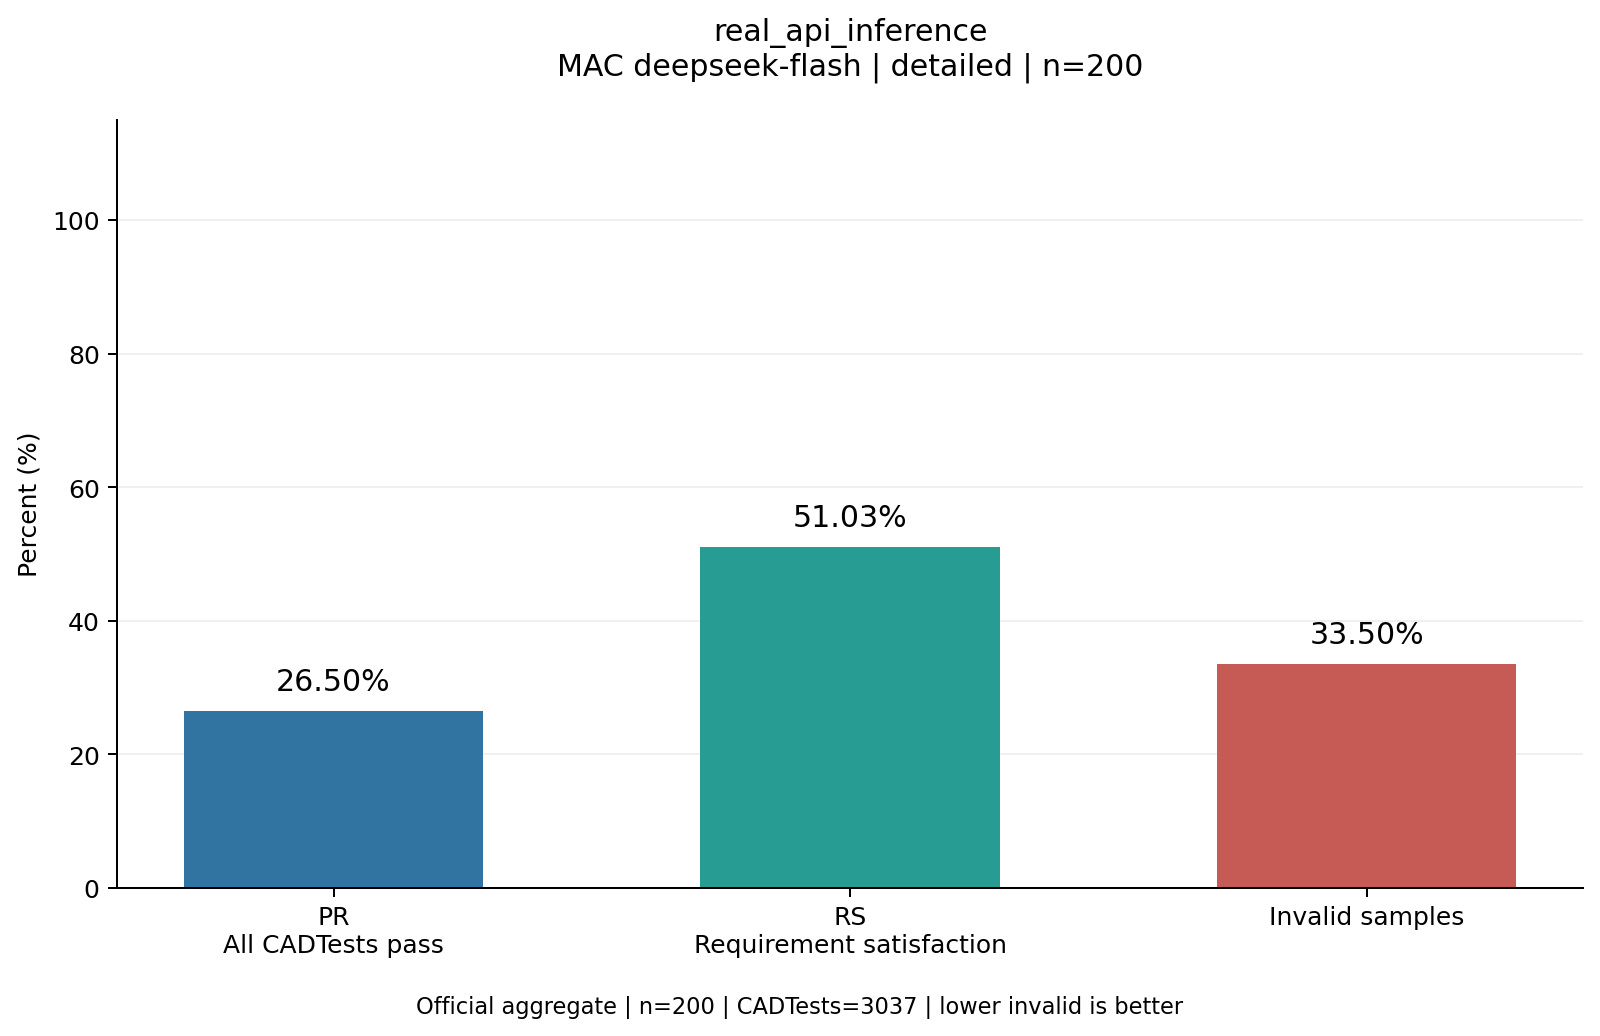

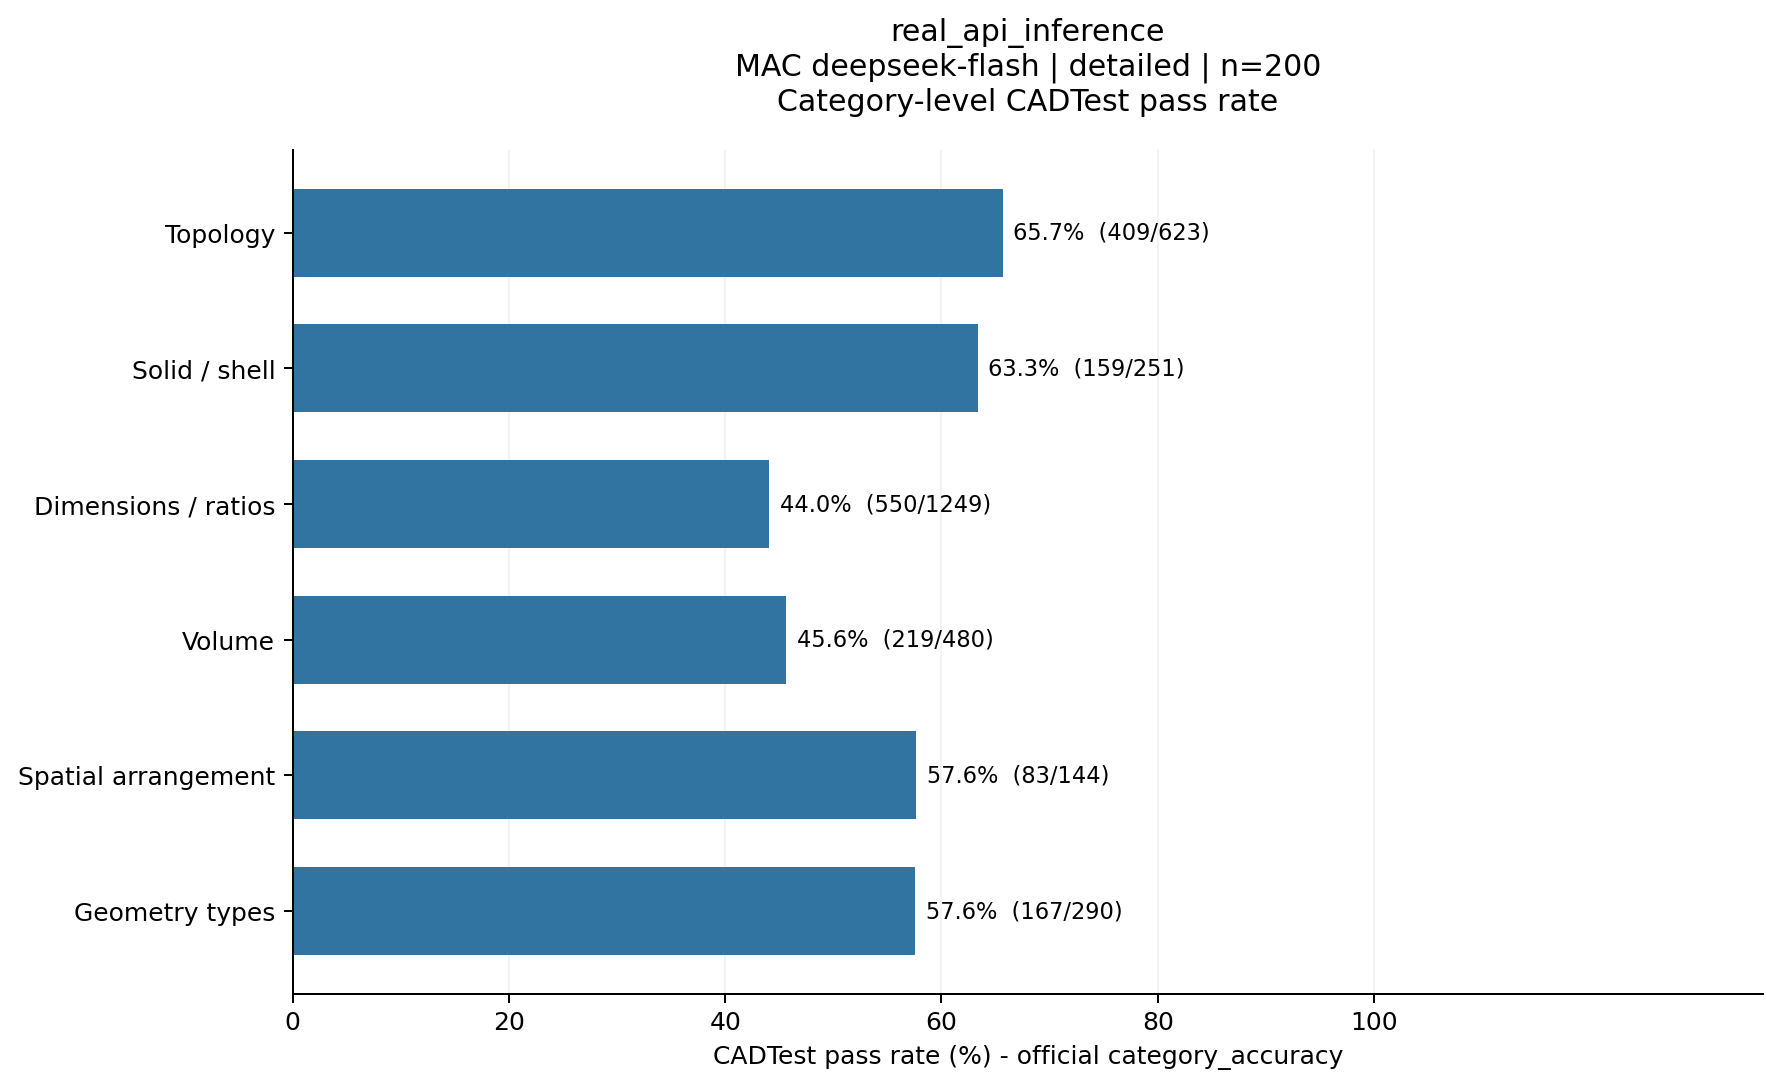

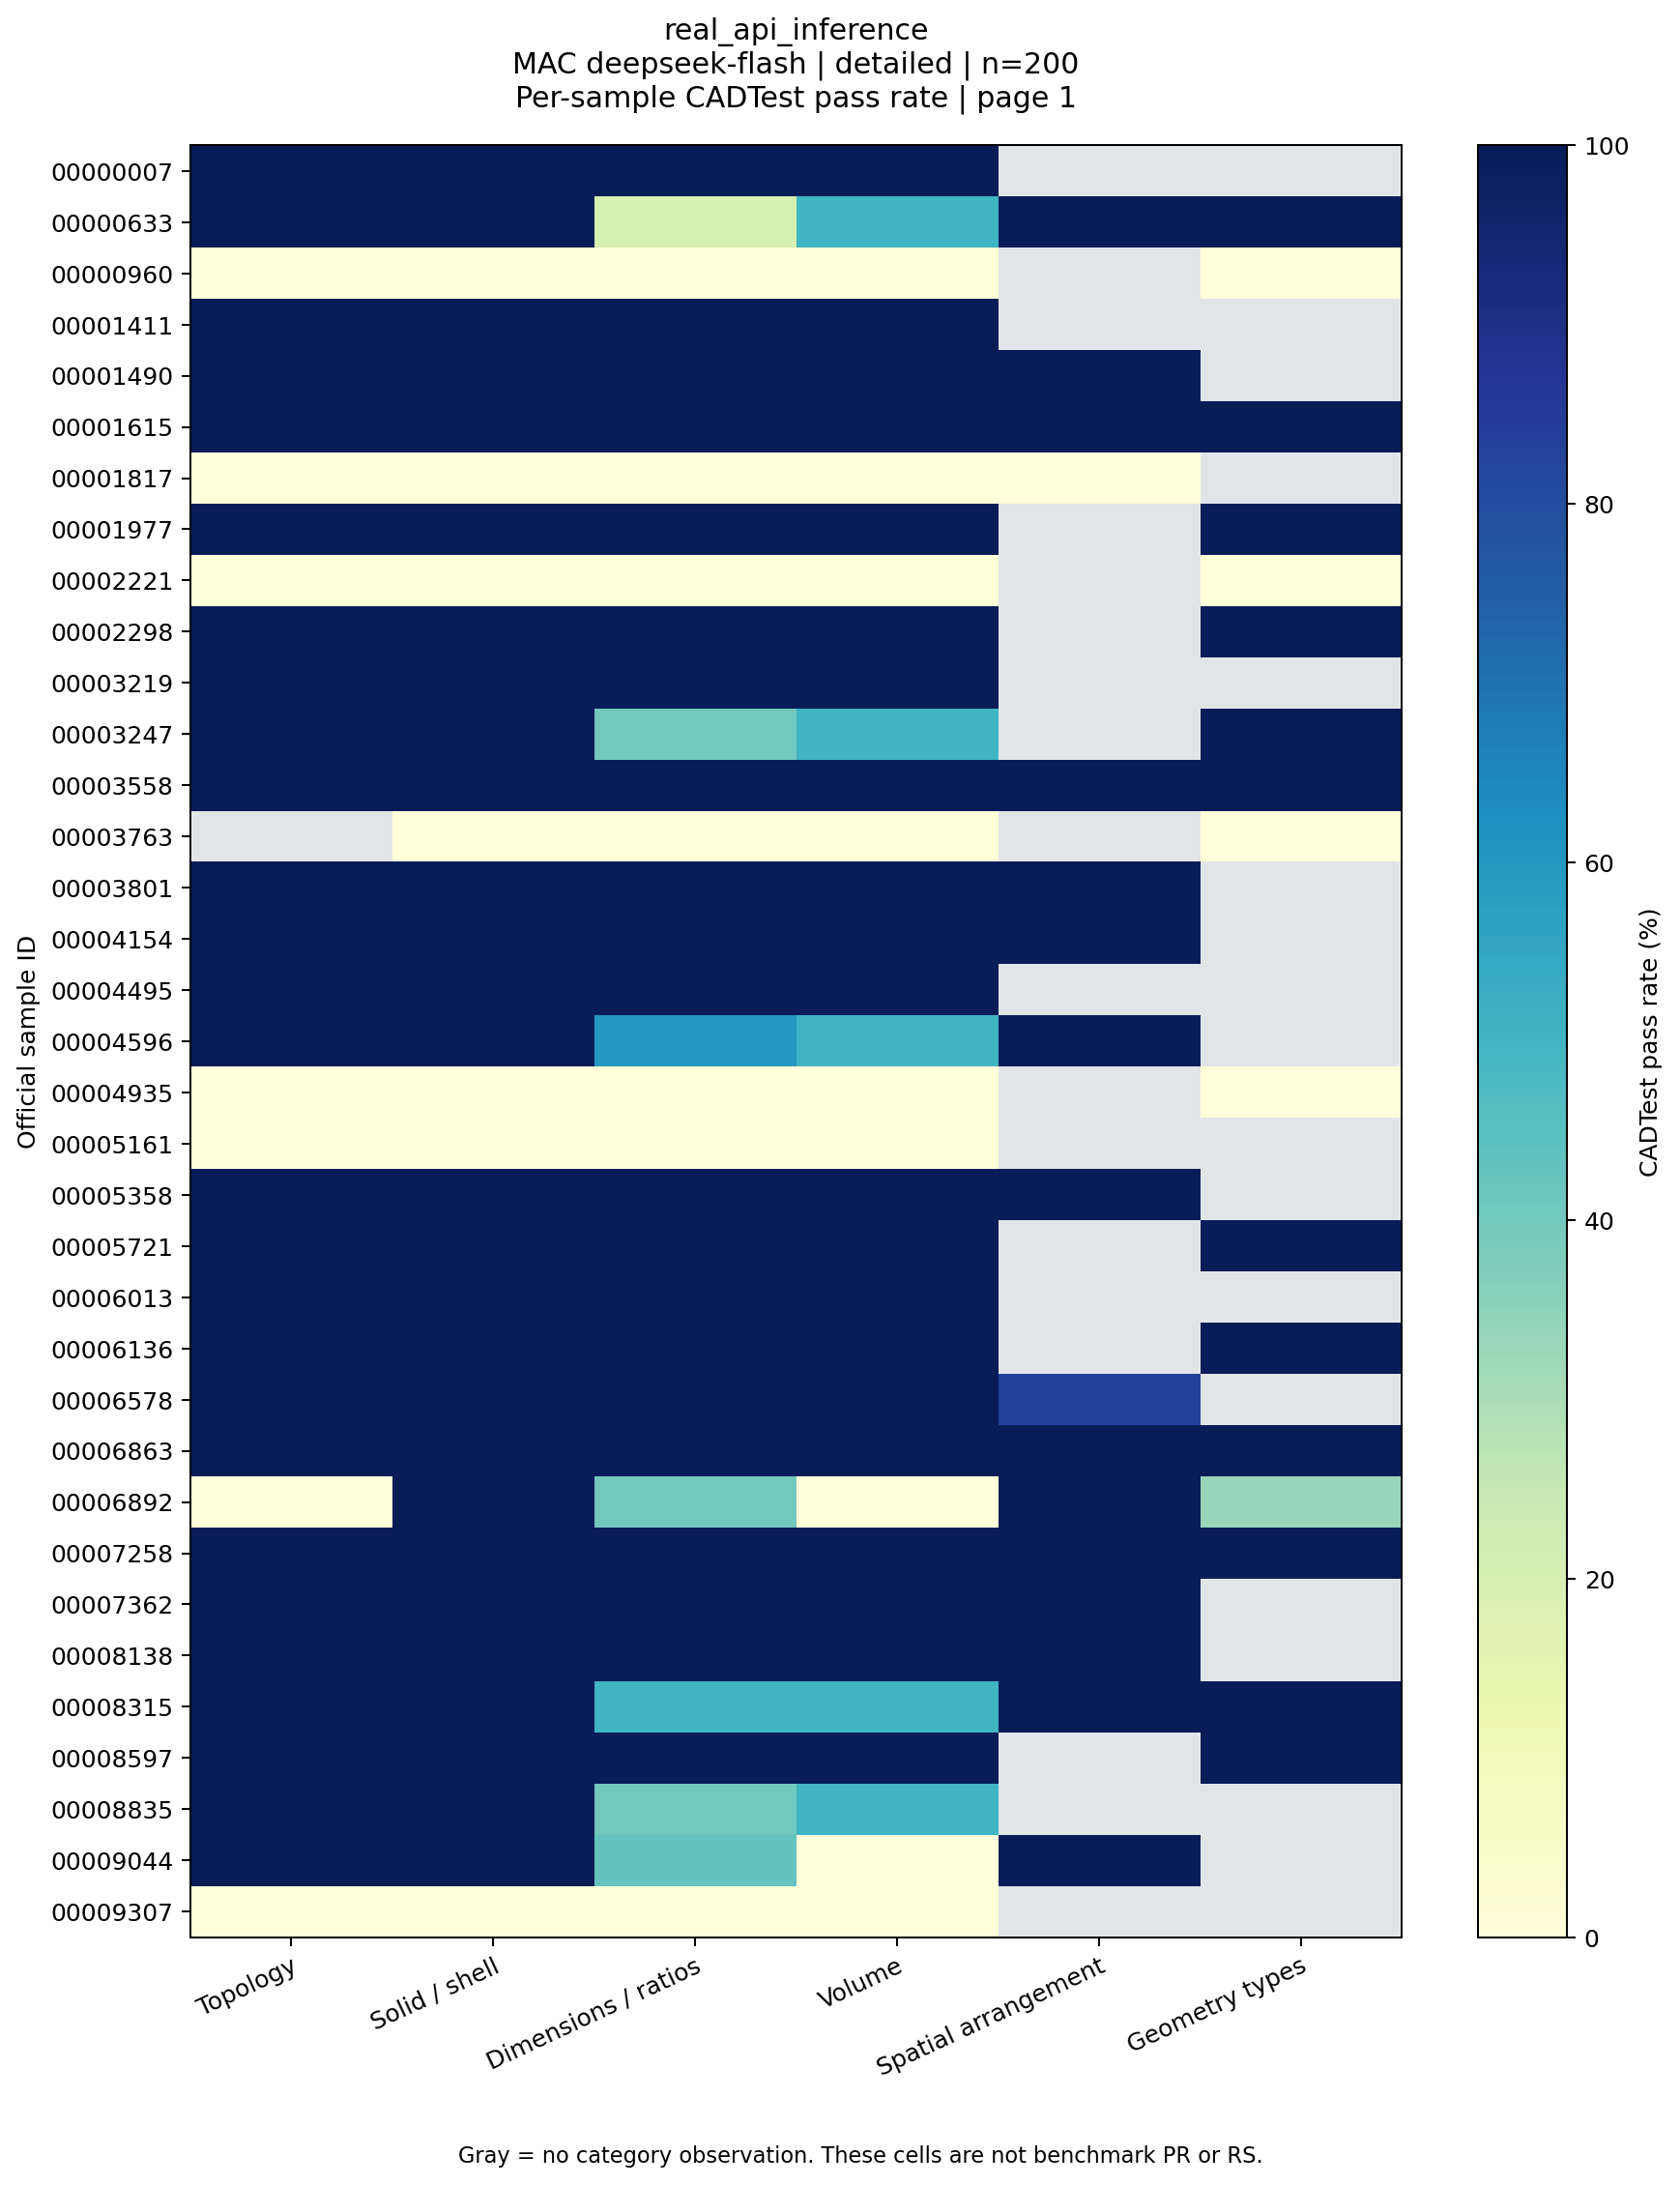

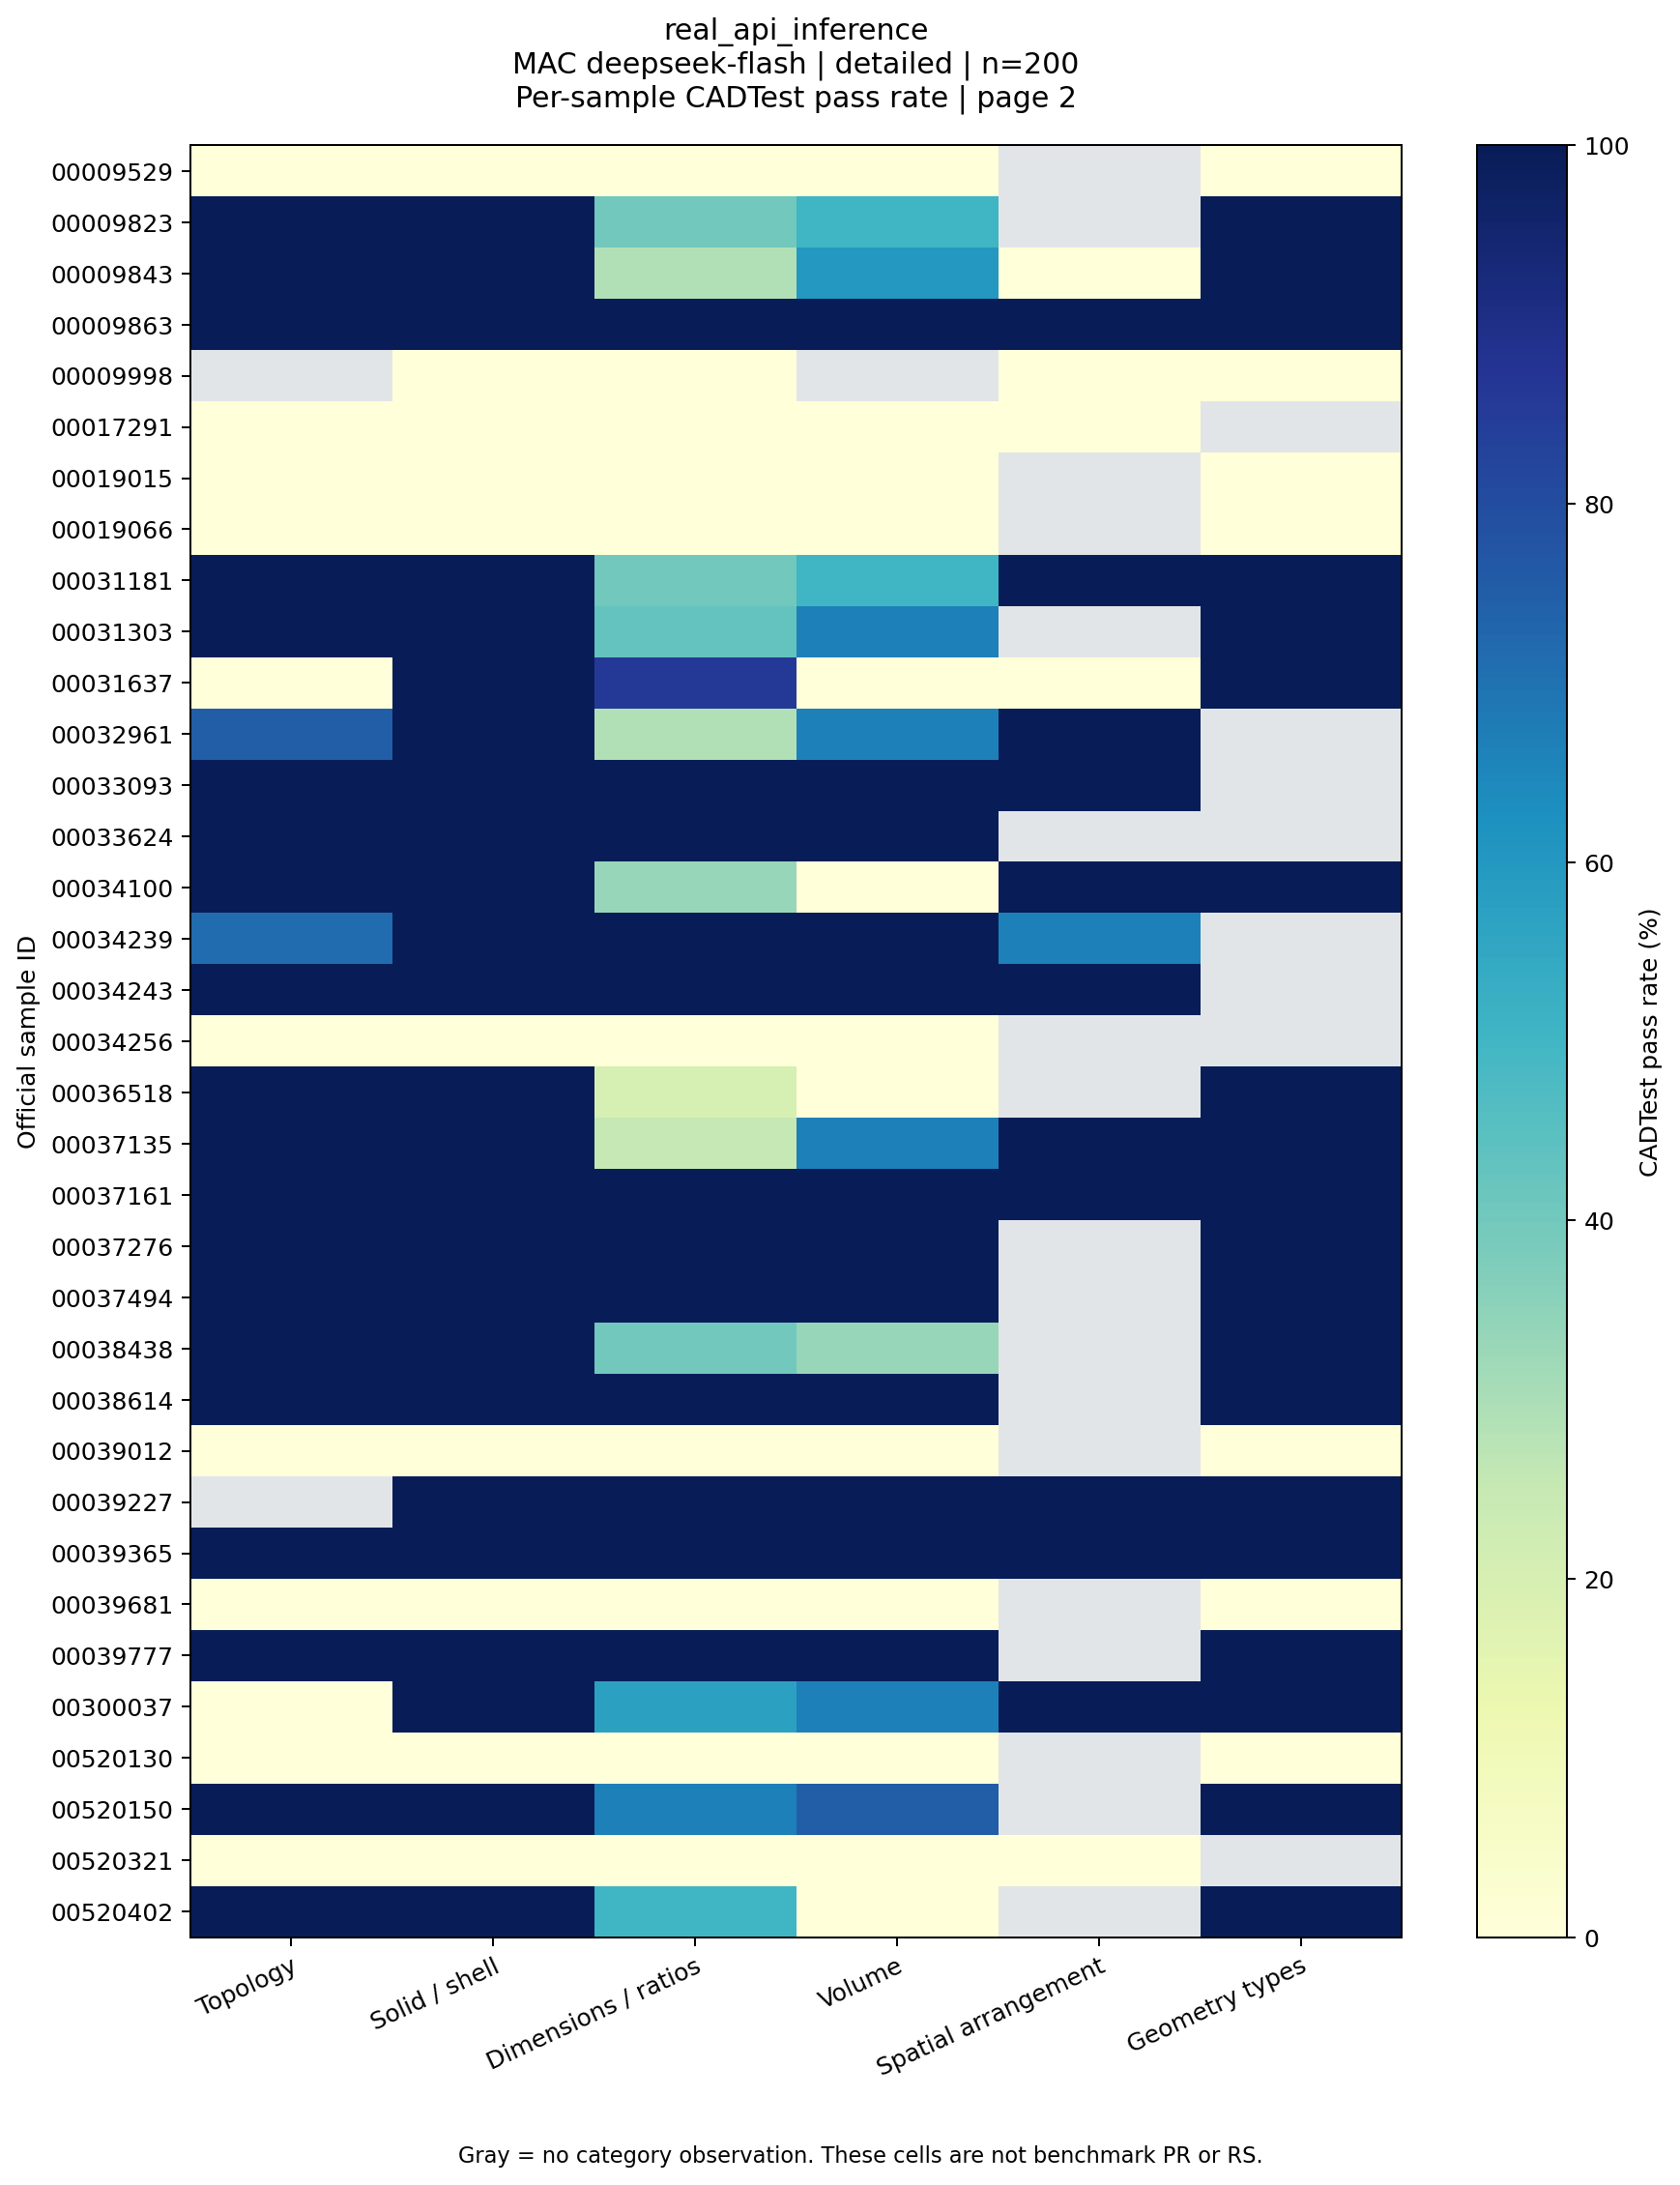

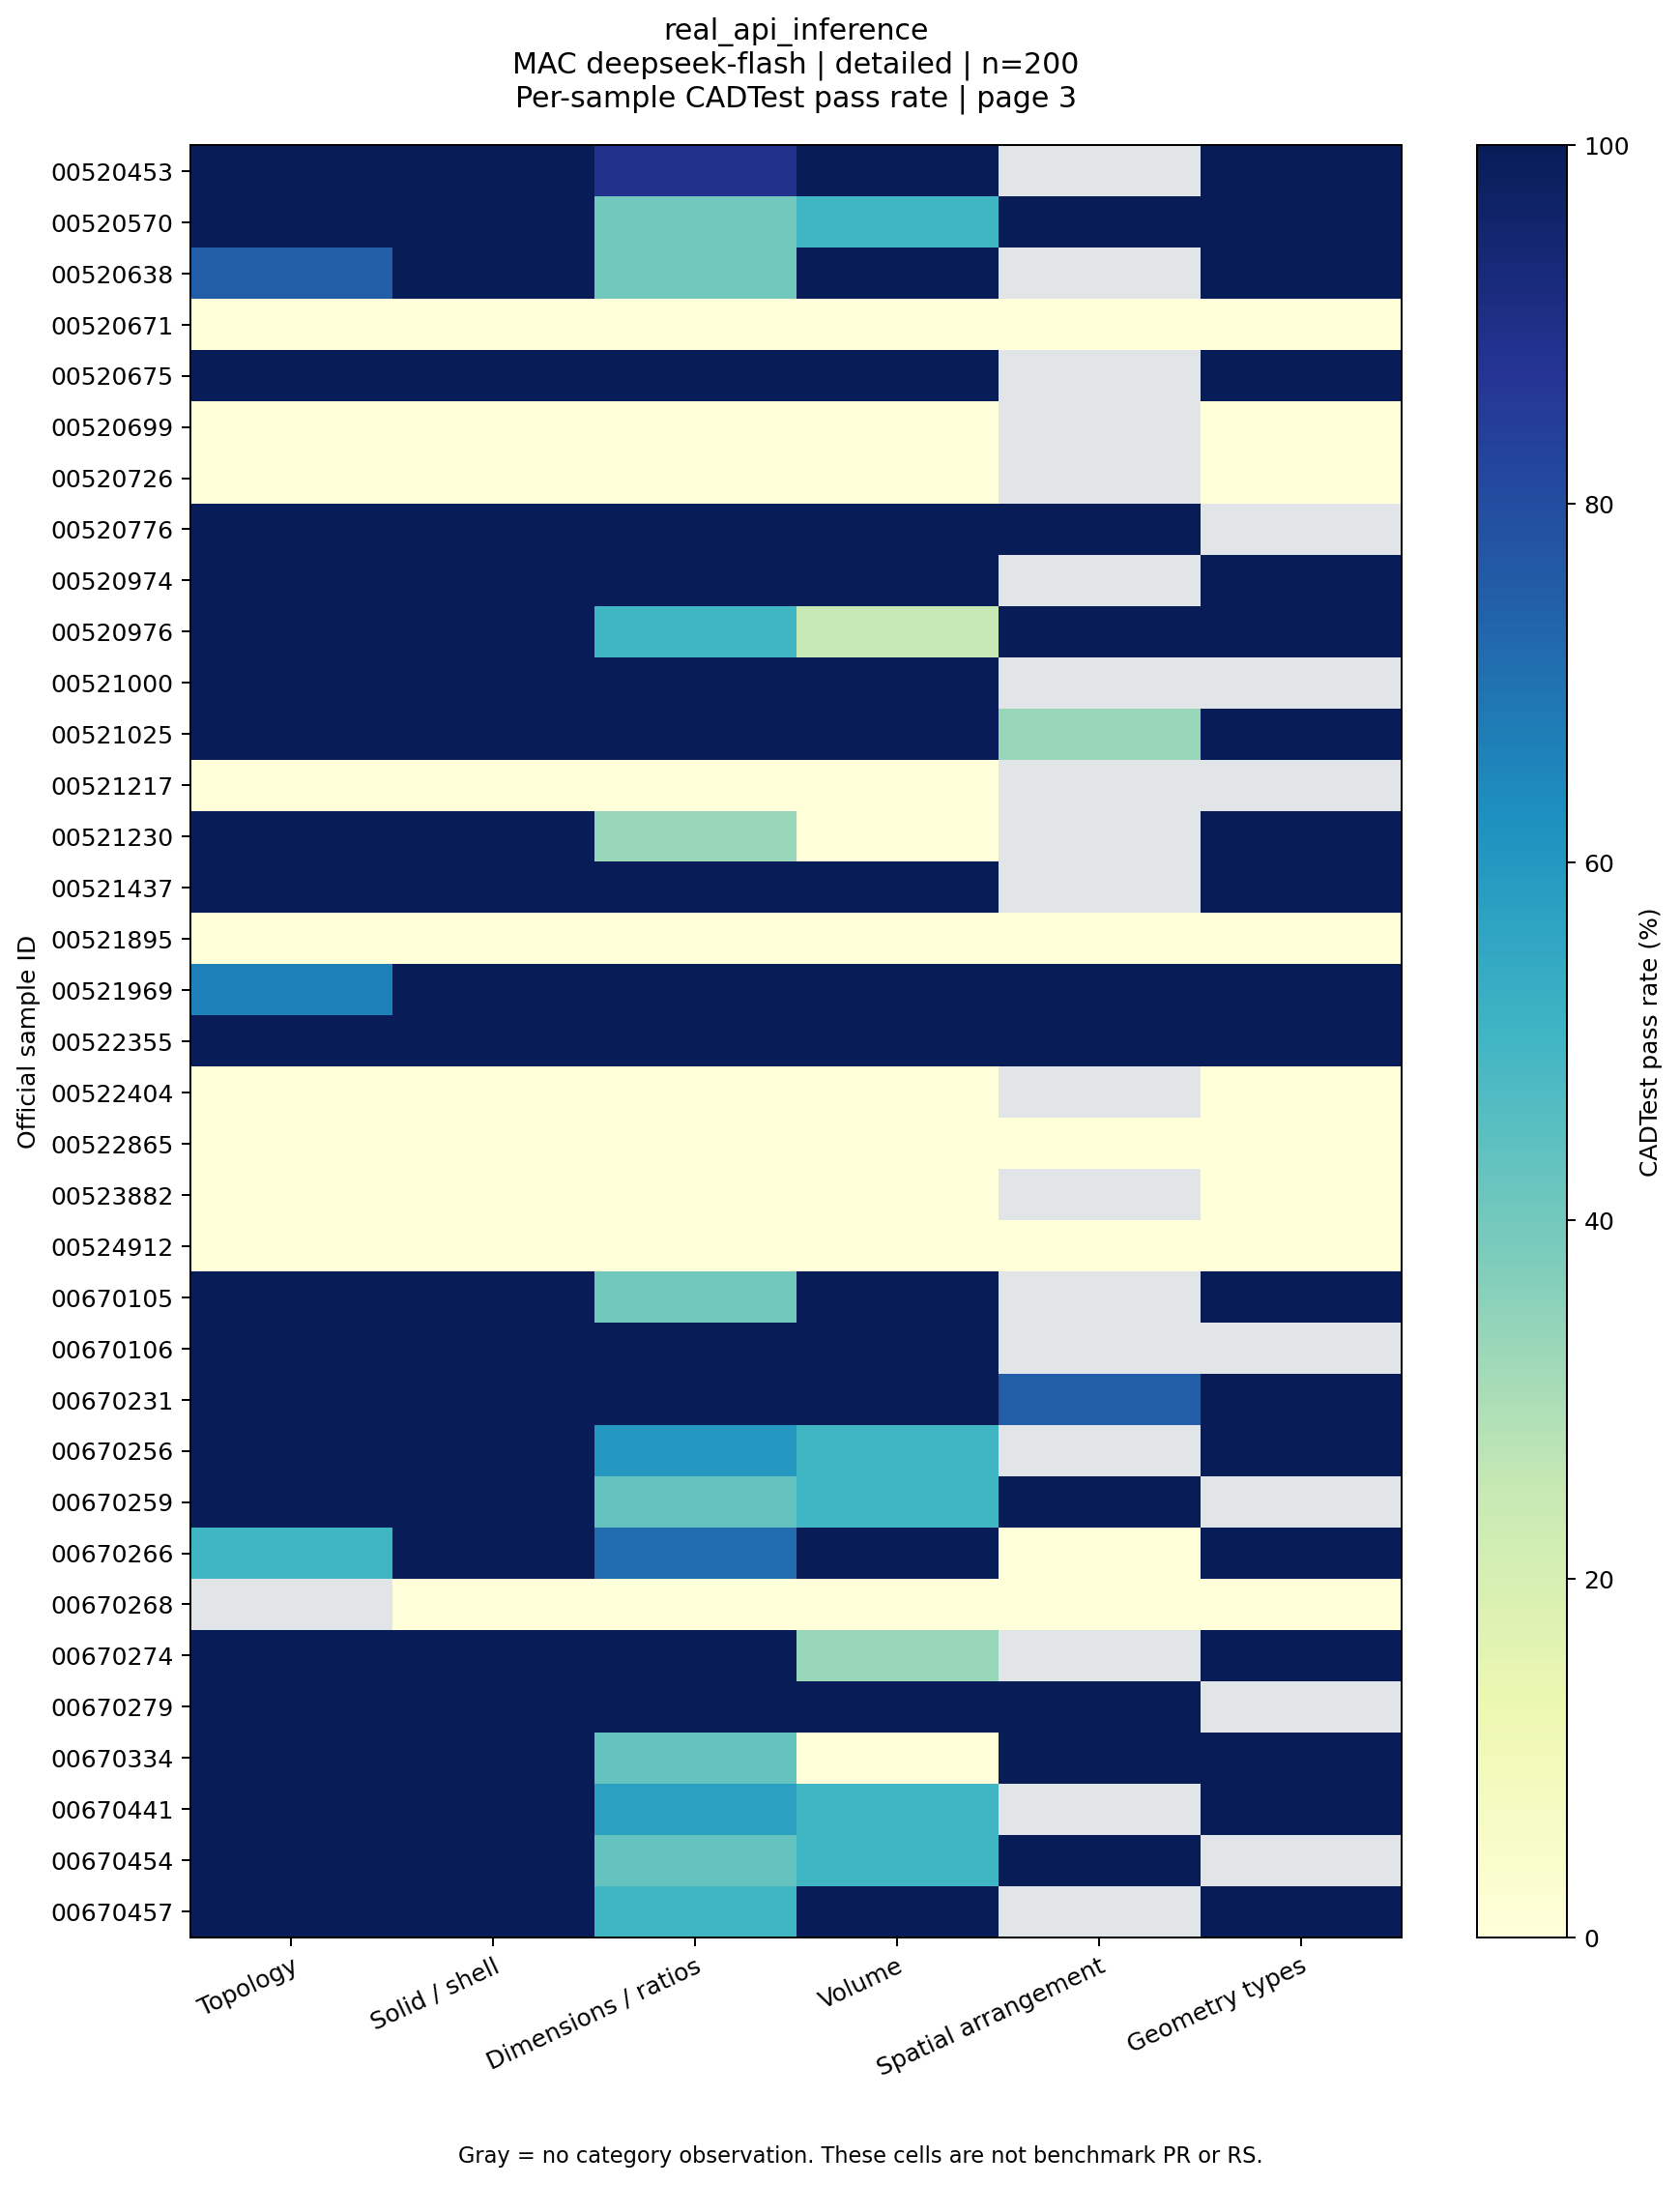

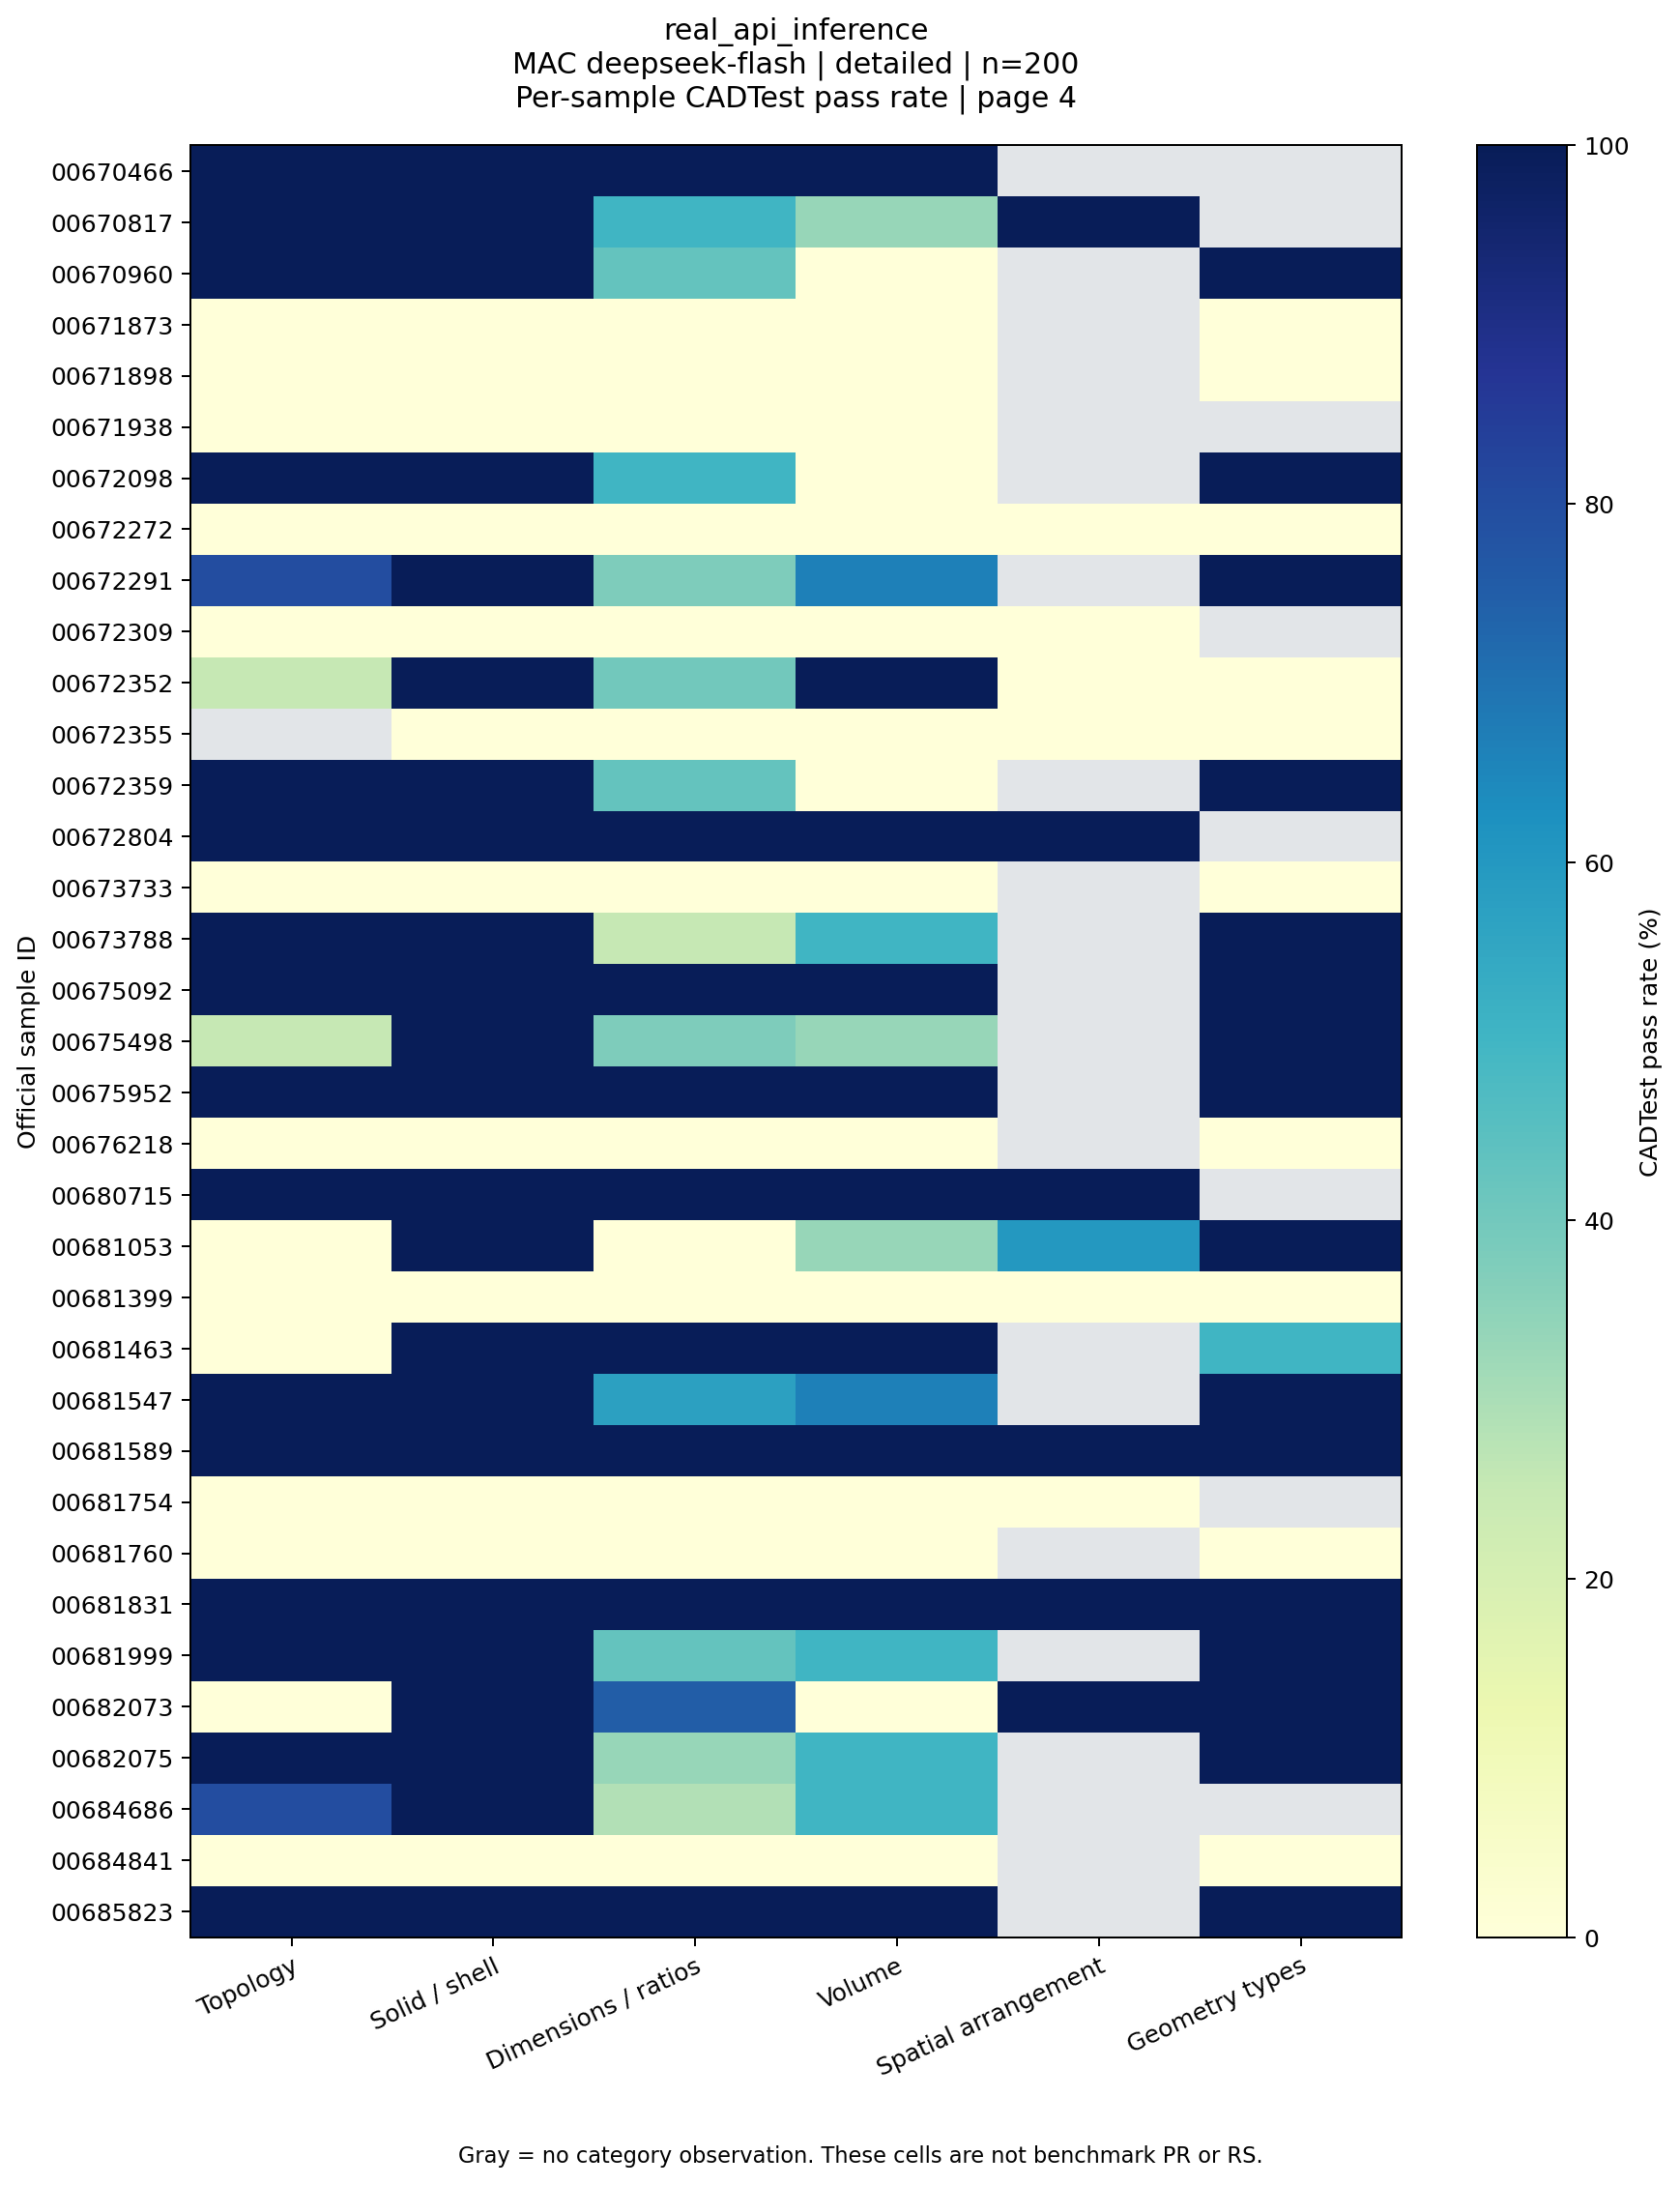

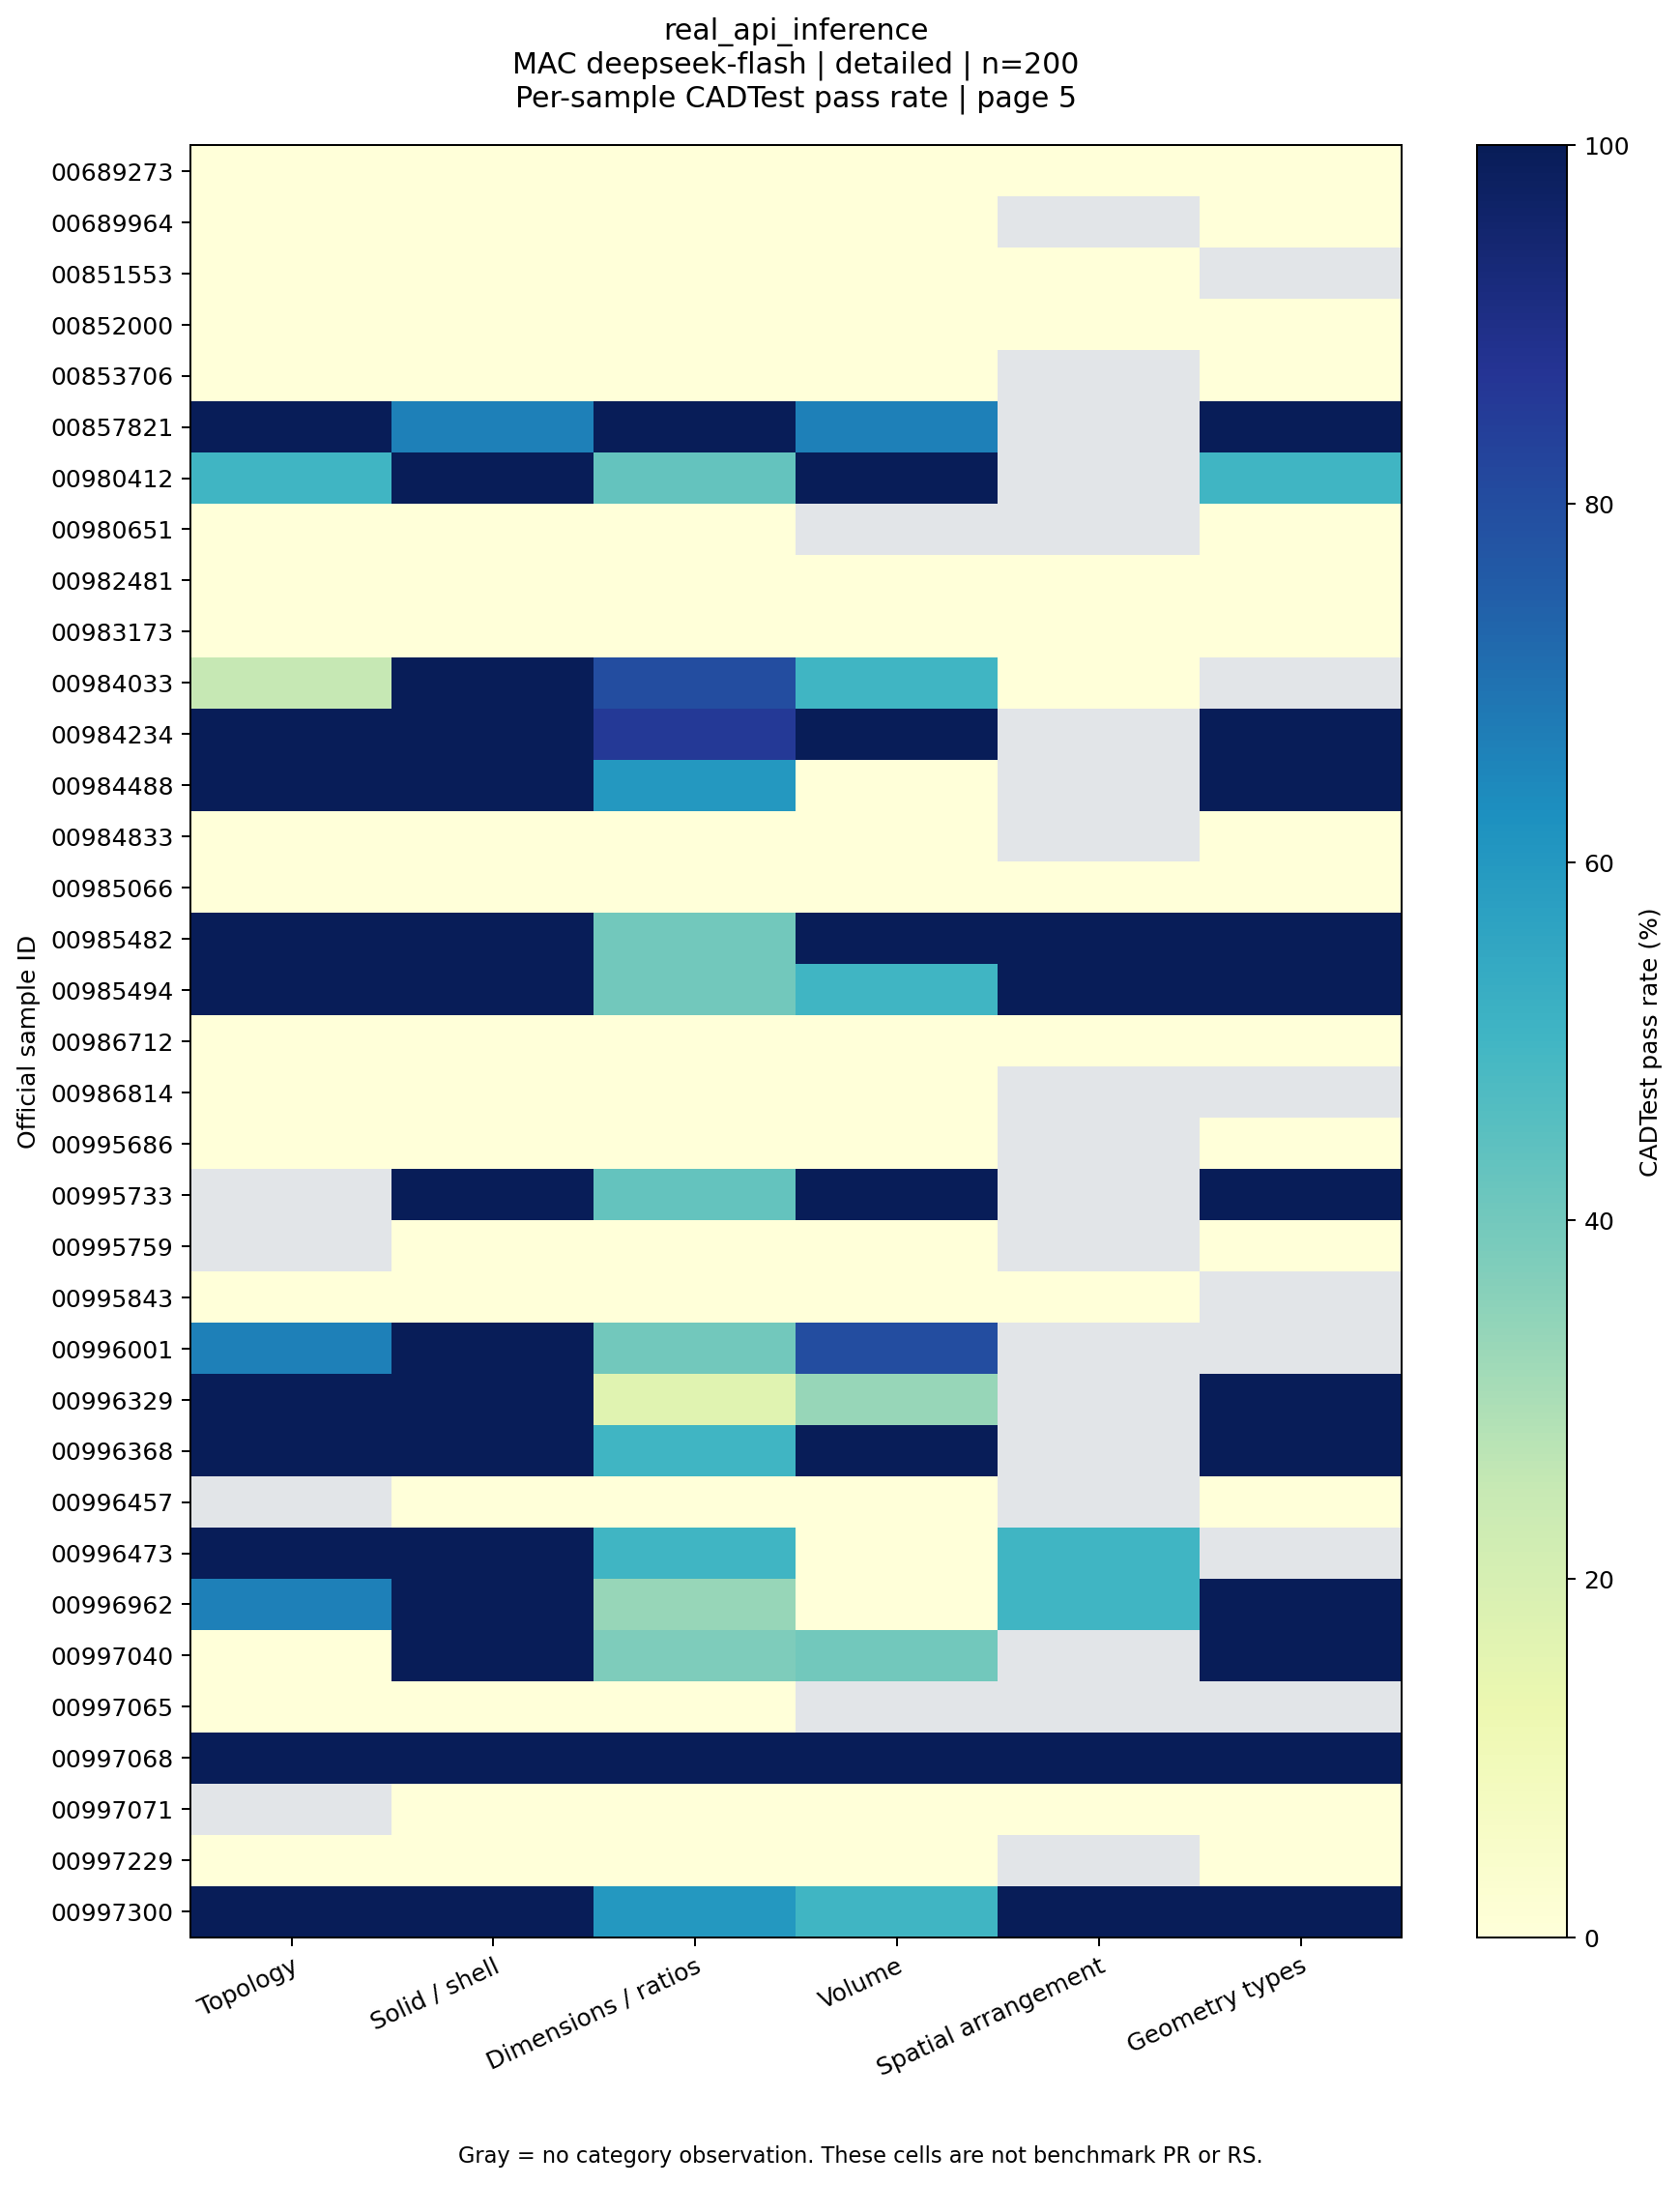

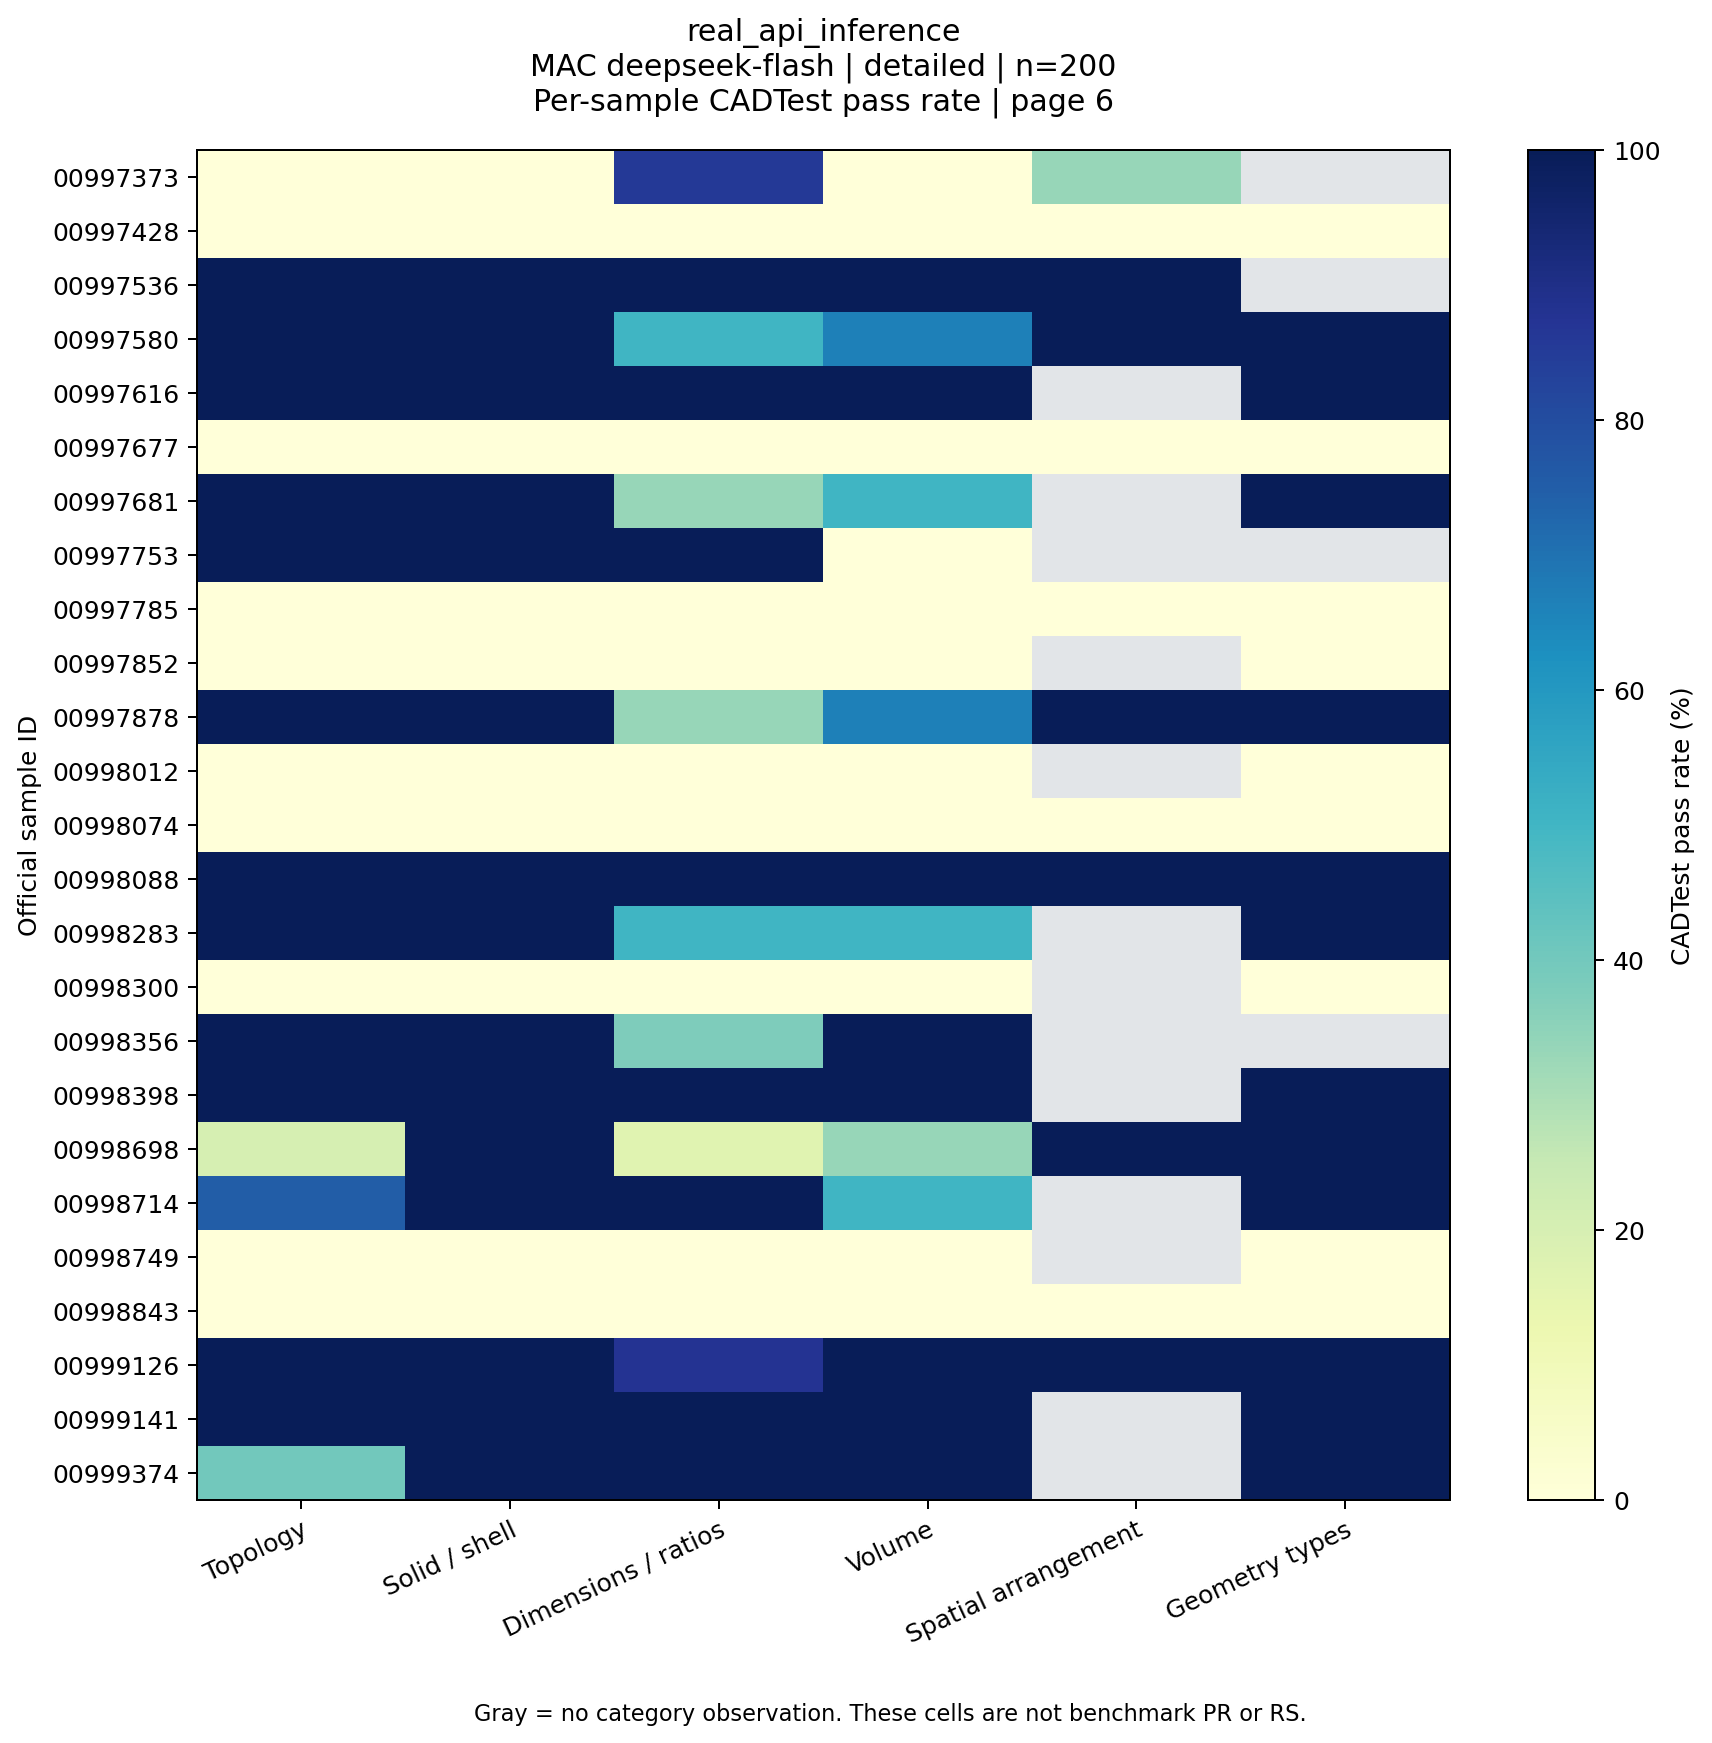

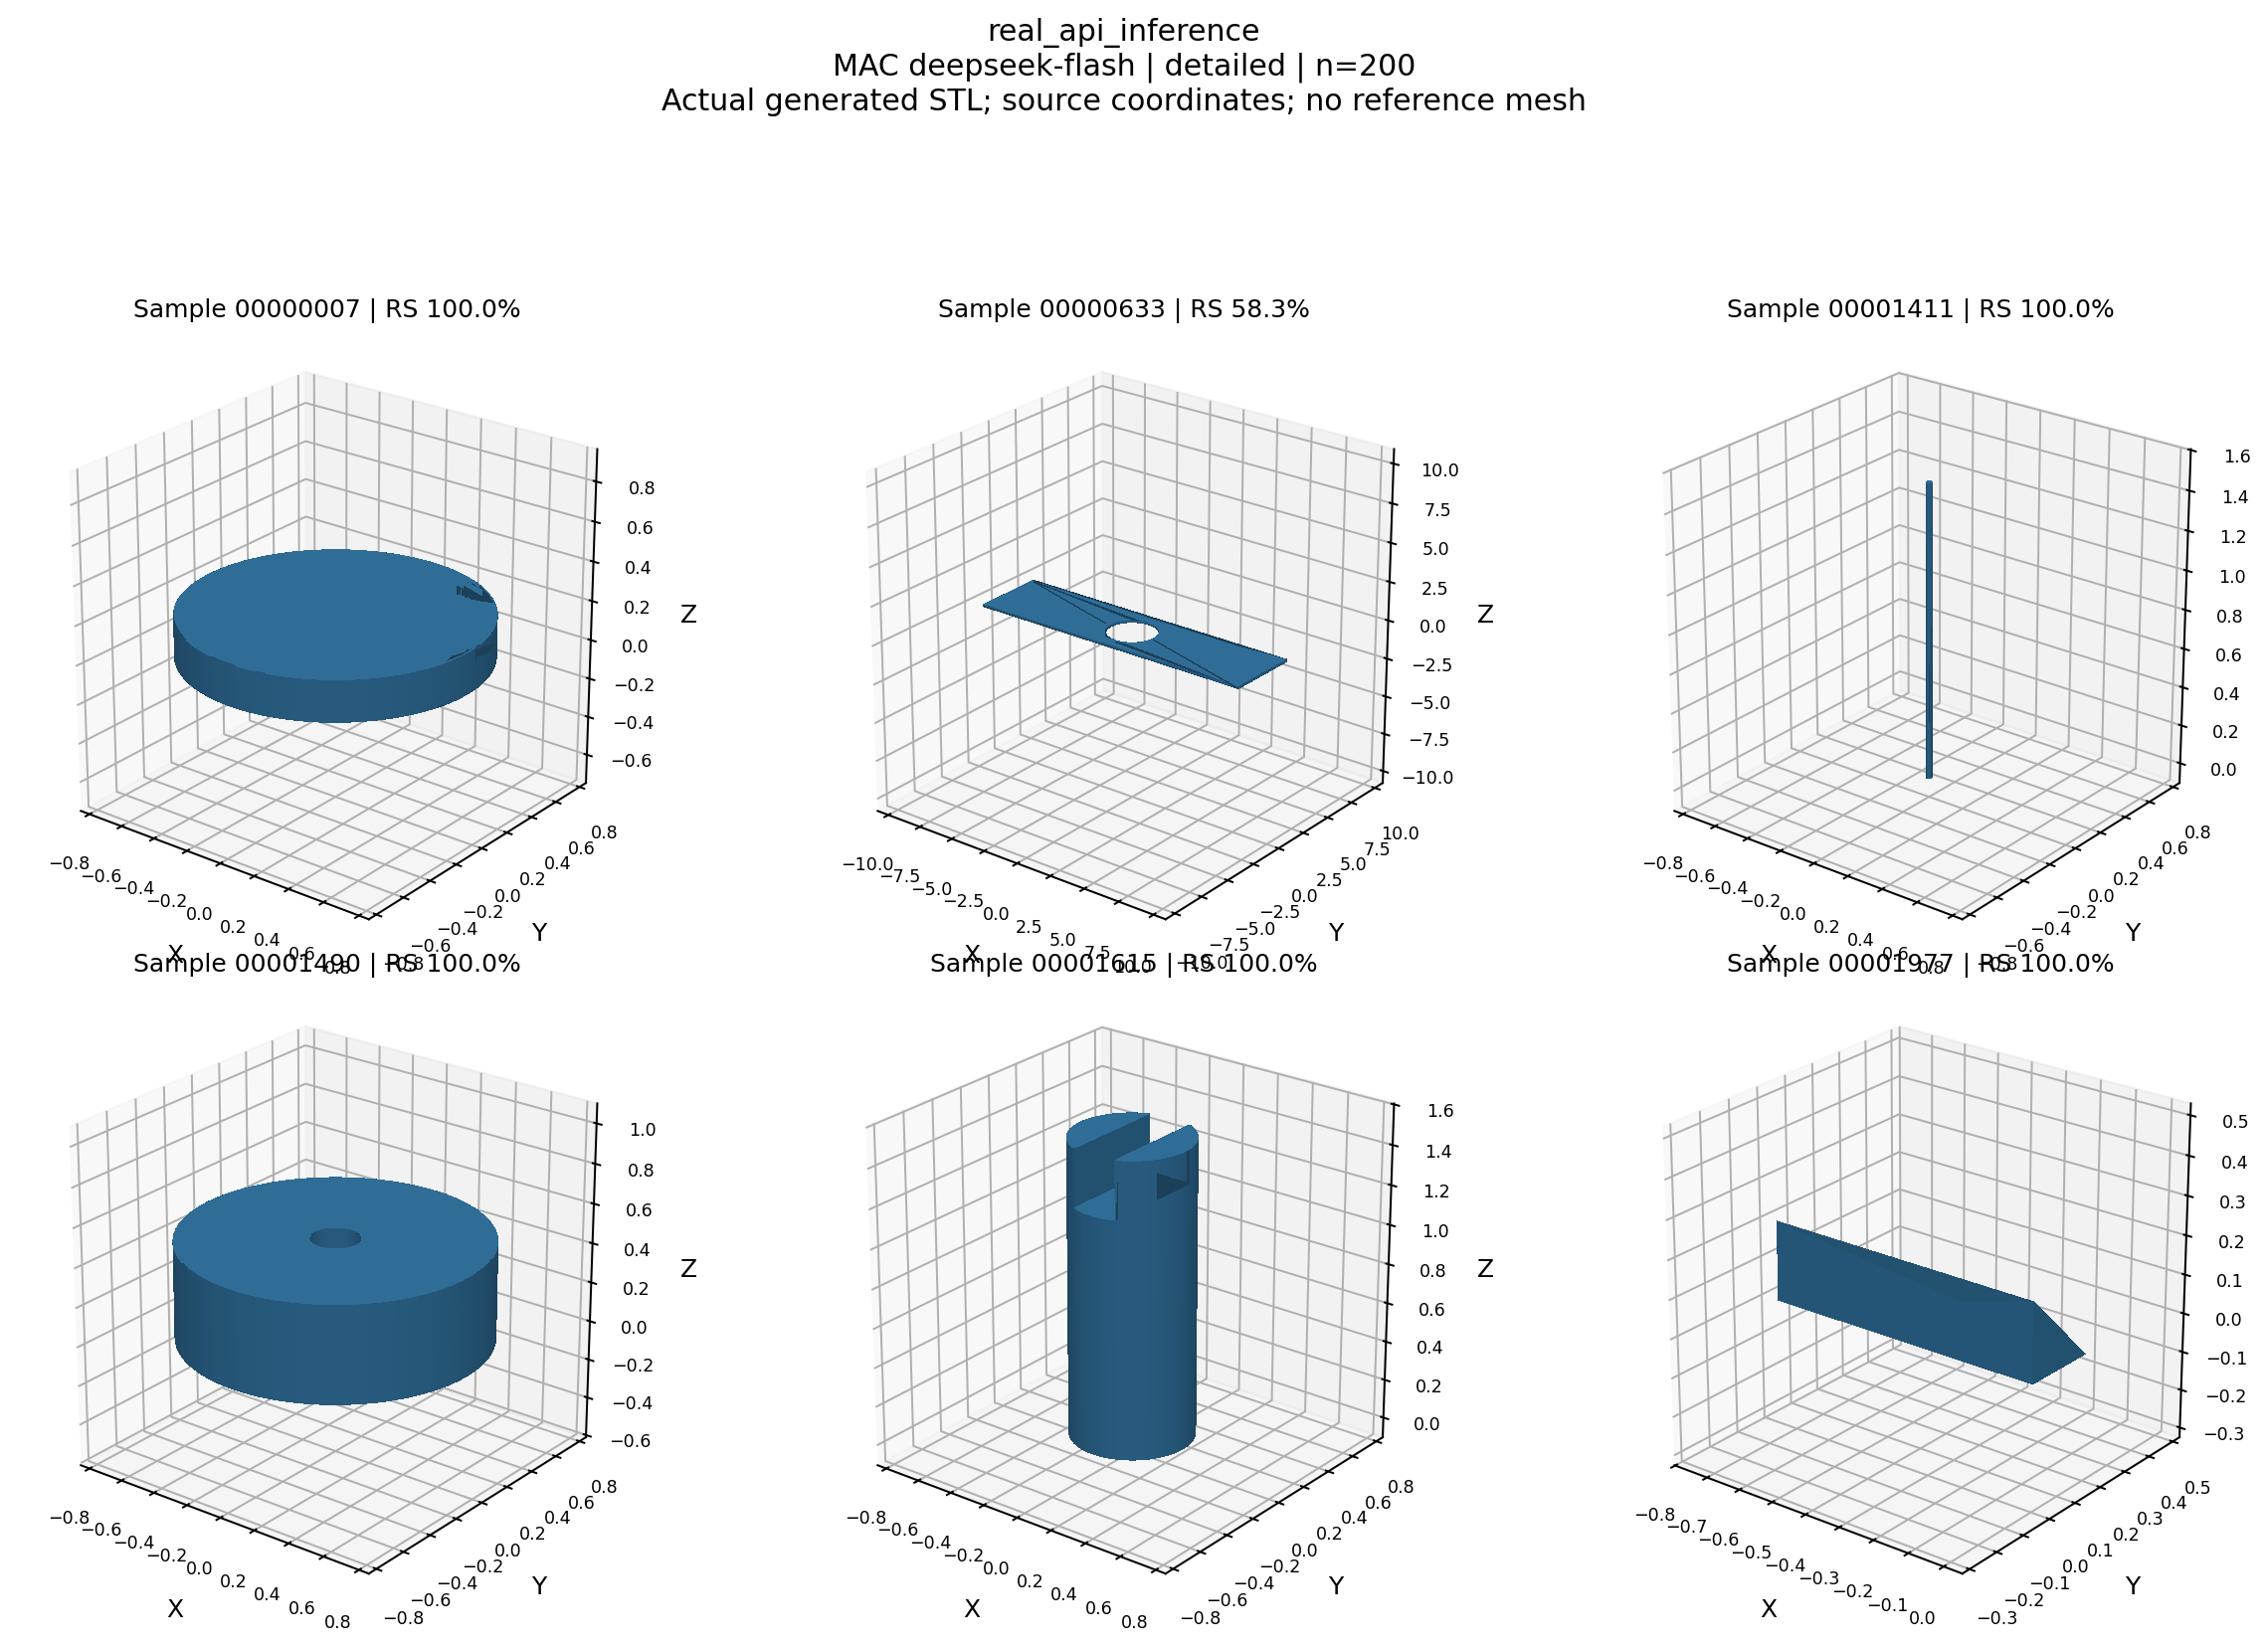

可旋转 CAD HTML： C:\Users\xuyq\Desktop\MAC_API_CADTestBench_project\mac_api_cadtestbench\outputs\mac_api_deepseek_deepseek-flash_text_20261101T080600Z_ecab62\figures\detailed\rotatable_cad.html


In [13]:
from ctb_plots import load_official_run, plot_official_metrics, plot_stl_gallery, write_stl_html

plot_index = []
for item in evaluations:
    partition = item['partition']
    title = f'MAC {API_MODEL} | {partition} | n={len(selected_ids)}'
    directory = RUN_DIR / 'figures' / partition
    paths = plot_official_metrics(item['output_dir'], run_kind='real_api_inference',
                                 title=title, out_dir=directory)
    gallery = plot_stl_gallery(item['output_dir'], run_kind='real_api_inference',
                               title=title, out_dir=directory, max_samples=6)
    if gallery:
        paths['cad_gallery'] = gallery
    for figure in paths.values():
        display(Image(filename=str(figure)))
    sample_frame = load_official_run(item['output_dir'])['samples']
    stls = sample_frame['generated_stl'].dropna().tolist() if not sample_frame.empty else []
    if stls:
        html = write_stl_html(stls[0], run_kind='real_api_inference', title=title,
                              output_html=directory / 'rotatable_cad.html')
        paths['interactive_html'] = html
        print('可旋转 CAD HTML：', html)
    plot_index.append({'partition': partition, 'paths': {k: str(v) for k, v in paths.items()}})
save_json(RUN_DIR / 'plot_index.json', plot_index)
